# W2 실험 진단: 무엇 때문에 결과가 달라졌나?

이 노트북은 **기존 다섯 정책을 수정하지 않고** 같은 seed의 입력을 네 방식으로 나눠 비교한다. 위에서 아래로 실행하면 결과 생성부터 Peak 근처 이벤트 확인까지 볼 수 있다. 저장된 출력은 5개 seed, 2×·4×의 실제 실행 결과다.

| 조건 | 도착 시각 | 도구 대기 |
|---|---|---|
| `base` | 원래 도착 | 기본 대기 × 강도 |
| `burst` | 10초 구간의 앞 1초에 집중 | 기본 대기 × 강도 |
| `wait` | 원래 도착 | 짧음·긺 교대 × 강도 |
| `both` | 집중 도착 | 짧음·긺 교대 × 강도 |

**읽기 전 주의:** `wait`는 대기 패턴뿐 아니라 평균 대기시간도 바꾼다. 이 표는 분산만의 효과를 측정하지 않는다. Duration-Aware는 실제 미래 대기시간을 예측값으로 쓰는 Oracle 참고선이다. 처리 속도는 실측 전 설정값이다.

## 1. 동일 설정으로 결과 준비

In [8]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'kvbench').exists():
    ROOT = ROOT.parent
assert (ROOT / 'kvbench').exists(), '노트북을 프로젝트 루트 또는 notebooks/에서 실행하세요.'
sys.path.insert(0, str(ROOT))

from kvbench.experiment import W2_FACTORIAL_CONDITIONS, W2_FACTORIAL_POLICIES, run_w2_factorial

OUTPUT = ROOT / 'results' / 'w2_factorial'
if not OUTPUT.exists():
    run_w2_factorial(
        ROOT / 'configs/week7.json',
        ROOT / 'configs/system_1080ti_llama3b.json',
        ROOT / 'configs/policies_week7.json',
        OUTPUT,
    )
manifest = json.loads((OUTPUT / 'experiment.json').read_text(encoding='utf-8'))
assert manifest['experiment'] == 'w2_factorial_diagnostic'
assert manifest['policies'] == list(W2_FACTORIAL_POLICIES)
assert manifest['seeds'] == list(range(5))
assert [(x['load'], x['workload'], x['stress_level']) for x in manifest['conditions']] == list(W2_FACTORIAL_CONDITIONS)

summary = pd.read_csv(OUTPUT / 'summary.csv')
comparison = pd.read_csv(OUTPUT / 'comparison.csv')
slo = pd.read_csv(OUTPUT / 'slo_by_seed.csv')
print(f'실험: {len(summary)} runs | {summary.policy.nunique()} policies | {summary.load.nunique()} conditions | {summary.seed.nunique()} seeds')
print(f'결과 경로: {OUTPUT}')

실험: 225 runs | 5 policies | 9 conditions | 5 seeds
결과 경로: C:\Users\user\Desktop\kv-bench\results\w2_factorial


## 2. 먼저 입력이 얼마나 달라졌는지

정책 결과를 보기 전에 도구 대기시간 자체를 확인한다. W1의 `base_2x`와 W2의 `both_2x`는 이름에 같은 2×가 있어도 평균 대기가 다르다.

In [9]:
condition_map = {label: (workload, level) for label, workload, level in W2_FACTORIAL_CONDITIONS}
input_rows = []
for label, (workload, level) in condition_map.items():
    waits = []
    for seed in range(5):
        trace = OUTPUT / 'traces' / f'{workload.lower()}_s{level}_seed{seed}.jsonl'
        frame = pd.read_json(trace, lines=True)
        waits.extend(frame.loc[frame.tool_duration_ms > 0, 'tool_duration_ms'].tolist())
    series = pd.Series(waits)
    input_rows.append({'condition': label, 'tool_calls': len(waits),
                       'mean_wait_s': series.mean() / 1000,
                       'median_wait_s': series.median() / 1000,
                       'p95_wait_s': series.quantile(0.95) / 1000})
input_table = pd.DataFrame(input_rows)
display(input_table.round(2))

,condition,tool_calls,mean_wait_s,median_wait_s,p95_wait_s
0,w0_1x,181,2.96,3.01,4.74
1,base_2x,181,5.93,6.02,9.48
2,burst_2x,181,5.93,6.02,9.48
3,wait_2x,181,11.29,2.19,37.41
4,both_2x,181,11.29,2.19,37.41
5,base_4x,181,11.85,12.05,18.97
6,burst_4x,181,11.85,12.05,18.97
7,wait_4x,181,22.57,4.38,74.82
8,both_4x,181,22.57,4.38,74.82


## 3. 기존 SLO와 실제 지표를 나란히 보기

SLO 통과 수는 **해당 정책의 동일 seed W0 대비 P95 TTFT 3배 이하**, 일반 요청 거절률 10% 이하, Peak KV 90% 이하를 모두 만족한 seed 수다. 옆의 절대 TTFT와 90% 초과 시간을 함께 읽는다. 90% 초과 시간은 모든 정책에서 같은 `[10초, 60초)` 구간으로 계산했다.

In [3]:
selected = comparison[comparison.load.isin(['both_2x', 'both_4x'])].copy()
selected['SLO 통과'] = (selected.all_slo_pass_rate_pct / 20).round().astype(int).astype(str) + '/5'
overview = selected[['load', 'policy', 'SLO 통과',
                     'normal_p95_ttft_ms_mean', 'peak_kv_occupancy_pct_mean',
                     'kv_above_90_ms_mean', 'recomputed_tokens_mean', 'transfer_bytes_mean']].copy()
overview.columns = ['조건', '정책', 'SLO 통과', 'P95 TTFT (ms)', 'Peak KV (%)',
                    '90% 초과 시간 (ms)', '재계산 토큰', '전송 바이트']
display(overview.round(1))

,조건,정책,SLO 통과,P95 TTFT (ms),Peak KV (%),90% 초과 시간 (ms),재계산 토큰,전송 바이트
4,both_2x,pin_all,0/5,6962.1,97.6,12943.0,0.0,0.000000e+00
8,both_4x,pin_all,0/5,13702.6,99.5,20426.5,0.0,0.000000e+00
13,both_2x,evict_recompute,5/5,666.3,61.1,0.0,126002.8,0.000000e+00
17,both_4x,evict_recompute,5/5,535.7,58.6,0.0,126002.8,0.000000e+00
22,both_2x,fixed_ttl,4/5,435.5,74.6,249.3,56310.8,0.000000e+00
26,both_4x,fixed_ttl,5/5,480.3,69.5,0.0,90750.6,0.000000e+00
31,both_2x,lru_offload,0/5,377.2,96.4,4981.7,0.0,9.549382e+08
35,both_4x,lru_offload,0/5,377.2,98.3,7895.8,0.0,2.789212e+09
40,both_2x,duration_aware,1/5,377.2,95.1,922.4,0.0,6.579605e+09
44,both_4x,duration_aware,2/5,377.2,91.3,565.7,0.0,6.365276e+09


### 같은 seed에서 상대 기준과 절대 시간을 비교

아래 표의 `W0 P95`가 정책마다 다르다. 따라서 절대 TTFT가 더 낮아도 자기 W0 대비 3배를 넘으면 TTFT 기준에서는 실패할 수 있다.

In [4]:
seed_example = slo[(slo.load == 'both_4x') & (slo.seed == 0) &
                   (slo.policy.isin(['duration_aware', 'fixed_ttl', 'evict_recompute']))]
display(seed_example[['policy', 'w0_p95_ttft_ms', 'normal_p95_ttft_ms',
                      'ttft_ratio_vs_policy_w0', 'ttft_pass', 'occupancy_pass', 'all_pass']].round(2))

,policy,w0_p95_ttft_ms,normal_p95_ttft_ms,ttft_ratio_vs_policy_w0,ttft_pass,occupancy_pass,all_pass
85,evict_recompute,530.74,849.82,1.60,True,True,True
130,fixed_ttl,454.93,765.75,1.68,True,True,True
220,duration_aware,194.06,613.31,3.16,False,False,False


## 4. 버스트와 교대 대기의 영향

아래 그림은 **동일 강도 안에서** 기본·버스트·교대·둘 다를 비교한다. 위에서 확인한 대로 교대 규칙은 평균 대기도 바꾸므로, 선 사이의 차이를 순수한 변동성 효과라고 부르지 않는다.

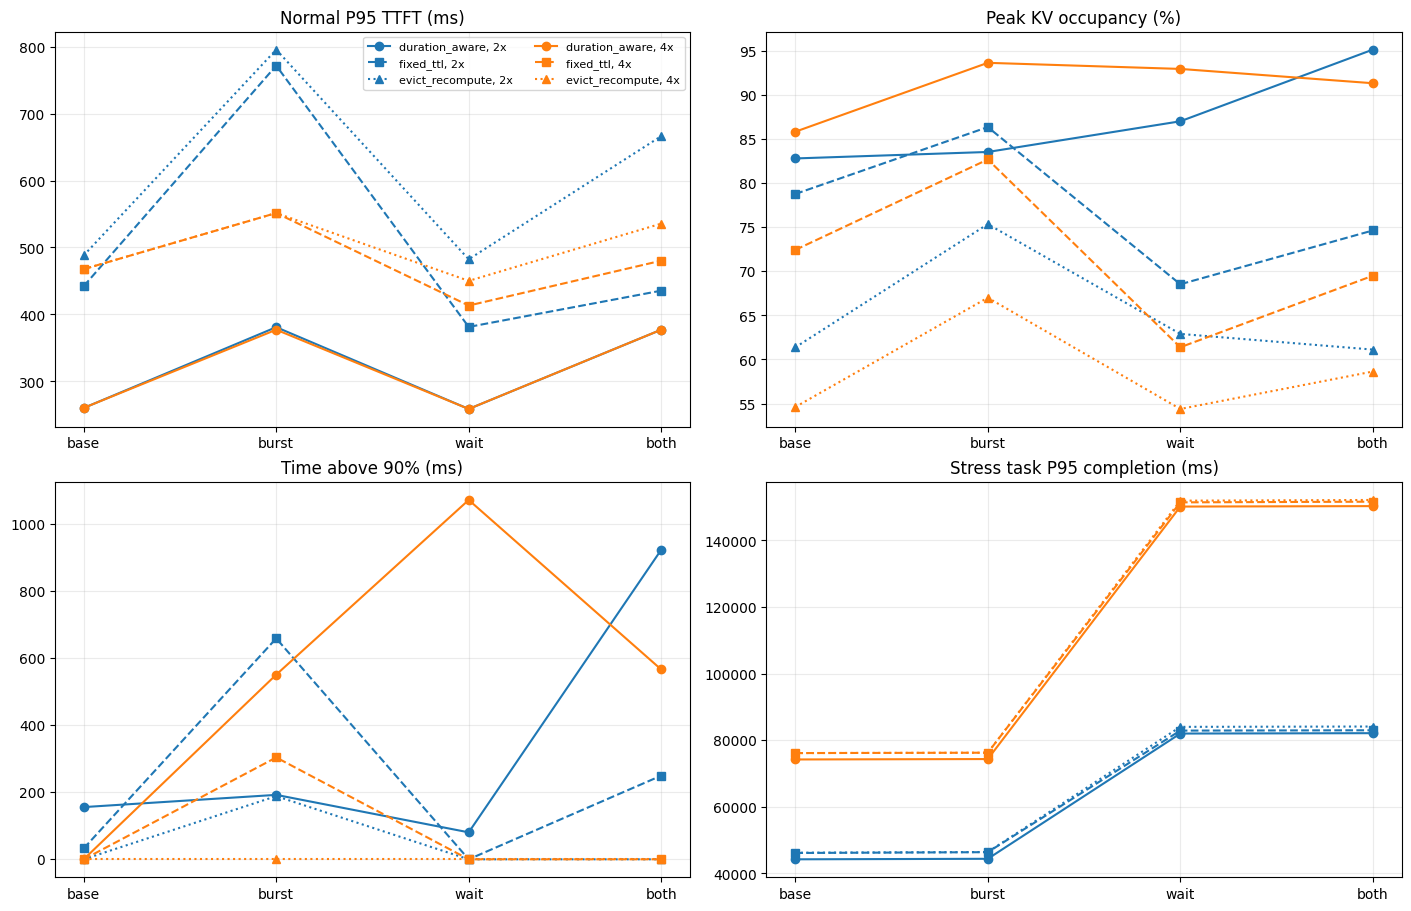

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
metrics = [
    ('normal_p95_ttft_ms_mean', 'Normal P95 TTFT (ms)'),
    ('peak_kv_occupancy_pct_mean', 'Peak KV occupancy (%)'),
    ('kv_above_90_ms_mean', 'Time above 90% (ms)'),
    ('stress_p95_completion_ms_mean', 'Stress task P95 completion (ms)'),
]
for level, color in [(2, 'tab:blue'), (4, 'tab:orange')]:
    labels = [f'{kind}_{level}x' for kind in ('base', 'burst', 'wait', 'both')]
    for policy, marker in [('duration_aware', 'o'), ('fixed_ttl', 's'), ('evict_recompute', '^')]:
        subset = comparison[(comparison.policy == policy)].set_index('load').reindex(labels)
        for ax, (metric, title) in zip(axes.flat, metrics):
            ax.plot(range(4), subset[metric], marker=marker, color=color,
                    linestyle='-' if policy == 'duration_aware' else '--' if policy == 'fixed_ttl' else ':',
                    label=f'{policy}, {level}x')
for ax, (_, title) in zip(axes.flat, metrics):
    ax.set_title(title)
    ax.set_xticks(range(4), ['base', 'burst', 'wait', 'both'])
    ax.grid(alpha=.25)
axes[0, 0].legend(fontsize=8, ncol=2)
plt.show()

## 5. Duration-Aware는 실제로 무엇을 선택했나?

현재 설정에서는 KEEP/OFFLOAD/EVICT 중 EVICT가 거의 또는 전혀 나타나지 않을 수 있다. 선택 횟수를 세어 3-way 판단이 실제로 평가되었는지 확인한다.

In [6]:
decision_rows = []
for load in ('both_2x', 'both_4x'):
    for seed in range(5):
        run = summary[(summary.policy == 'duration_aware') &
                      (summary.load == load) & (summary.seed == seed)].iloc[0]
        events = pd.read_csv(OUTPUT / 'runs' / run.run_id / 'events.csv')
        decisions = events.loc[events.event == 'TOOL_START', 'detail'].str.extract(r'decision=(\w+)')[0].value_counts()
        decision_rows.append({'load': load, 'seed': seed,
                              'KEEP': int(decisions.get('keep', 0)),
                              'OFFLOAD': int(decisions.get('offload', 0)),
                              'EVICT': int(decisions.get('evict', 0))})
decisions = pd.DataFrame(decision_rows)
display(decisions.groupby('load')[['KEEP', 'OFFLOAD', 'EVICT']].sum())

,KEEP,OFFLOAD,EVICT
load,,,
both_2x,140,41,0
both_4x,142,39,0


## 6. Peak 순간의 이벤트 확인

W2 4× Duration-Aware에서 Peak가 가장 높은 seed를 골라, Peak 주변의 결정·할당·전송 이벤트를 보여준다. 같은 시각에 여러 이벤트가 있으면 `occupancy.csv`의 행 순서가 순간 Peak를 결정한다.

선택된 run: w2_s4_seed2__duration_aware, Peak: 97.78% at 30991.4 ms


,time_ms,event,session_id,detail
0,30007.619077,ADMIT,stress-000006,blocks=+157 held=157 wait_ms=0.0
1,30142.358771,ADMIT,normal-000068,blocks=+19 held=19 wait_ms=0.0
2,30282.573046,ADMIT,stress-000007,blocks=+156 held=156 wait_ms=0.0
3,30665.141444,ADMIT,normal-000069,blocks=+24 held=24 wait_ms=0.0
4,30866.665412,ADMIT,stress-000008,blocks=+213 held=213 wait_ms=0.0
5,30903.701025,ADMIT,stress-000009,blocks=+201 held=201 wait_ms=0.0
6,30991.441176,ADMIT,stress-000010,blocks=+168 held=168 wait_ms=0.0
7,31387.051130,TOOL_START,stress-000005,wait_ms=74864 decision=offload gpu_used_blocks...
8,31387.051130,OFFLOAD_START,stress-000005,bytes=346816512 reason=idle done_at=31416.0
9,31391.522369,ADMIT,normal-000070,blocks=+34 held=34 wait_ms=0.0


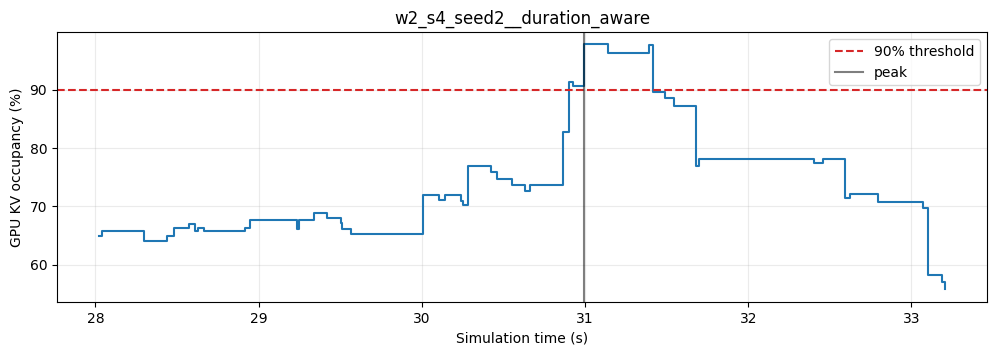

In [10]:
candidate = summary[(summary.policy == 'duration_aware') &
                    (summary.load == 'both_4x')].sort_values('peak_kv_occupancy_pct', ascending=False).iloc[0]
run_dir = OUTPUT / 'runs' / candidate.run_id
occupancy = pd.read_csv(run_dir / 'occupancy.csv')
occupancy['used_pct'] = occupancy.used_blocks / occupancy.total_blocks * 100
measured = occupancy[occupancy.time_ms >= manifest['workload_config']['warmup_ms']]
peak_row = measured.loc[measured.used_pct.idxmax()]
events = pd.read_csv(run_dir / 'events.csv')
near = events[(events.time_ms >= peak_row.time_ms - 1000) &
              (events.time_ms <= peak_row.time_ms + 1000) &
              (events.event.isin(['ADMIT', 'TOOL_START', 'OFFLOAD_START', 'OFFLOAD_DONE', 'EVICT', 'REJECT']))]
print(f'선택된 run: {candidate.run_id}, Peak: {peak_row.used_pct:.2f}% at {peak_row.time_ms:.1f} ms')
display(near[['time_ms', 'event', 'session_id', 'detail']].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(12, 3.5))
window = occupancy[(occupancy.time_ms >= peak_row.time_ms - 3000) &
                   (occupancy.time_ms <= peak_row.time_ms + 3000)]
ax.step(window.time_ms / 1000, window.used_pct, where='post')
ax.axhline(90, color='tab:red', linestyle='--', label='90% threshold')
ax.axvline(peak_row.time_ms / 1000, color='black', alpha=.5, label='peak')
ax.set(xlabel='Simulation time (s)', ylabel='GPU KV occupancy (%)', title=candidate.run_id)
ax.legend()
ax.grid(alpha=.25)
plt.show()

## 이 노트북으로 내릴 수 있는 결론의 범위

- 같은 trace 안에서 정책별 TTFT·점유율·비용 차이를 비교할 수 있다.
- `base`와 `burst`를 비교하면 도착 집중의 영향을 분리할 수 있다. `base`와 `wait`의 차이에는 대기 패턴 변화와 평균 대기 증가가 함께 포함된다.
- 기존 SLO 통과율만으로 절대 응답속도나 재계산 비용의 우열을 판단하지 않는다.
- 현재 Duration-Aware의 예상 대기는 실제 미래 대기를 사용한다. 현실형 예측 정책의 결과가 아니다.
- 모델의 prefill·decode·PCIe 값은 실측 전이다. 실제 GPU 성능을 주장하려면 보정과 민감도 분석이 추가로 필요하다.

## 7. 전체 실행 결과: 모든 정책 · 워크로드 · seed

아래 **두 표**는 9개 워크로드 조건 × 5개 정책 × 5개 seed = 225개 실행을 정책 → 워크로드 → seed 순으로 보여준다. 첫 표는 SLO 판정에 쓰이는 지표만, 둘째 표는 원인 분석용 부수 지표를 담았다. 코드 셀 맨 위의 `LOADS_TO_SHOW`, `POLICIES_TO_SHOW`, `SEEDS_TO_SHOW`를 바꾸면 두 표가 함께 필터링된다. 기본값 `None`은 전체 표시다.

`TTFT 배율`은 같은 정책·seed의 W0 1× 대비 값이다. 최종 SLO는 TTFT 배율 ≤ 3, 일반 요청 거부율 ≤ 10%, Peak KV ≤ 90%를 모두 만족해야 통과한다. `90% 초과 시간`은 10~60초 구간이고, Peak는 워밍업 10초 이후 실행 종료까지의 최고값이다.

In [11]:
from IPython.display import HTML

# None이면 전체 표시. 예: ['both_2x', 'both_4x'], ['duration_aware'], [0, 3, 4]
LOADS_TO_SHOW = None
POLICIES_TO_SHOW = None
SEEDS_TO_SHOW = None

expected = pd.MultiIndex.from_product(
    [manifest['policies'], [item['load'] for item in manifest['conditions']], manifest['seeds']],
    names=['policy', 'load', 'seed'],
).to_frame(index=False)
all_results = expected.merge(summary, on=['load', 'policy', 'seed'], how='left', validate='one_to_one')
all_results = all_results.merge(
    slo[['load', 'policy', 'seed', 'w0_p95_ttft_ms', 'ttft_ratio_vs_policy_w0',
         'ttft_pass', 'reject_pass', 'occupancy_pass', 'all_pass']],
    on=['load', 'policy', 'seed'], how='left', validate='one_to_one',
)
assert len(all_results) == 225 and all_results.run_id.notna().all() and all_results.all_pass.notna().all()

shown = all_results
for column, allowed in [('load', LOADS_TO_SHOW), ('policy', POLICIES_TO_SHOW), ('seed', SEEDS_TO_SHOW)]:
    if allowed is not None:
        shown = shown[shown[column].isin(allowed)]

slo_table = pd.DataFrame({
    '정책': shown.policy, '워크로드': shown.load, 'seed': shown.seed,
    'W0 P95 TTFT (ms)': shown.w0_p95_ttft_ms.round(2),
    'P95 TTFT (ms)': shown.normal_p95_ttft_ms.round(2),
    'TTFT 배율': shown.ttft_ratio_vs_policy_w0.round(2),
    'TTFT 판정': shown.ttft_pass.map({True: '통과', False: '실패'}),
    '일반 요청 거부율 (%)': shown.normal_reject_rate_pct.round(2),
    '거부율 판정': shown.reject_pass.map({True: '통과', False: '실패'}),
    'Peak KV (%)': shown.peak_kv_occupancy_pct.round(2),
    'Peak 판정': shown.occupancy_pass.map({True: '통과', False: '실패'}),
    '최종 SLO': shown.all_pass.map({True: '통과', False: '실패'}),
})
secondary_table = pd.DataFrame({
    '정책': shown.policy, '워크로드': shown.load, 'seed': shown.seed,
    '90% 초과 시간 (초)': (shown.kv_above_90_ms / 1000).round(3),
    '90% 초과 비율 (%)': shown.kv_above_90_pct_of_time.round(2),
    '평균 KV (%)': shown.mean_kv_occupancy_pct.round(2),
    'Stress P95 완료 (초)': (shown.stress_p95_completion_ms / 1000).round(2),
    '작업 완료 평균 (초)': (shown.task_completion_mean_ms / 1000).round(2),
    '작업 완료 P95 (초)': (shown.task_completion_p95_ms / 1000).round(2),
    '일반 P50 TTFT (ms)': shown.normal_p50_ttft_ms.round(2),
    '전체 P95 TTFT (ms)': shown.all_p95_ttft_ms.round(2),
    '처리량 (작업/초)': shown.throughput_jobs_per_s.round(4),
    '일반 제출 수': shown.normal_submitted,
    '일반 완료 수': shown.normal_completed,
    '일반 거부 수': shown.normal_rejected,
    '완료 작업 수': shown.completed_jobs,
    '거부 작업 수': shown.rejected_jobs,
    'Stress 제출 수': shown.stress_submitted_jobs,
    'Stress 완료 수': shown.stress_completed_jobs,
    'Evict 횟수': shown.eviction_count,
    'Evict/완료작업': shown.eviction_per_job.round(3),
    'Offload 횟수': shown.offload_count,
    'Reload 횟수': shown.reload_count,
    '전송량 (GiB)': (shown.transfer_bytes / 2**30).round(3),
    '전송량/완료작업 (GiB)': shown.transfer_gib_per_job.round(3),
    '재계산 토큰': shown.recomputed_tokens,
    '재계산 토큰/완료작업': shown.recomputed_tokens_per_job.round(2),
    'Prefill 사용률 (%)': shown.prefill_busy_pct.round(2),
    'PCIe 사용률 (%)': shown.pcie_busy_pct.round(2),
    '전체 세션 수': shown.sessions,
    '실행 종료 (초)': (shown.end_ms / 1000).round(2),
})
for title, frame in [('SLO 판정', slo_table), ('부수 지표', secondary_table)]:
    display(HTML(
        f'<h3>{title}</h3><p>표시: {len(frame)} / {len(all_results)}개 실행</p>'
        '<div style="max-height:650px; max-width:100%; overflow:auto; border:1px solid #ddd">'
        + frame.to_html(index=False, escape=True) + '</div>'
    ))

정책,워크로드,seed,W0 P95 TTFT (ms),P95 TTFT (ms),TTFT 배율,TTFT 판정,일반 요청 거부율 (%),거부율 판정,Peak KV (%),Peak 판정,최종 SLO
pin_all,w0_1x,0,194.06,194.06,1.00,통과,0.00,통과,63.12,통과,통과
pin_all,w0_1x,1,239.74,239.74,1.00,통과,0.00,통과,74.15,통과,통과
pin_all,w0_1x,2,243.48,243.48,1.00,통과,0.00,통과,76.11,통과,통과
pin_all,w0_1x,3,375.11,375.11,1.00,통과,0.00,통과,57.05,통과,통과
pin_all,w0_1x,4,241.49,241.49,1.00,통과,0.00,통과,61.03,통과,통과
pin_all,base_2x,0,194.06,194.06,1.00,통과,0.00,통과,94.32,실패,실패
pin_all,base_2x,1,239.74,247.18,1.03,통과,0.00,통과,84.79,통과,통과
pin_all,base_2x,2,243.48,243.48,1.00,통과,0.00,통과,97.35,실패,실패
pin_all,base_2x,3,375.11,375.11,1.00,통과,0.00,통과,71.50,통과,통과
pin_all,base_2x,4,241.49,241.49,1.00,통과,0.00,통과,78.29,통과,통과


정책,워크로드,seed,90% 초과 시간 (초),90% 초과 비율 (%),평균 KV (%),Stress P95 완료 (초),작업 완료 평균 (초),작업 완료 P95 (초),일반 P50 TTFT (ms),전체 P95 TTFT (ms),처리량 (작업/초),일반 제출 수,일반 완료 수,일반 거부 수,완료 작업 수,거부 작업 수,Stress 제출 수,Stress 완료 수,Evict 횟수,Evict/완료작업,Offload 횟수,Reload 횟수,전송량 (GiB),전송량/완료작업 (GiB),재계산 토큰,재계산 토큰/완료작업,Prefill 사용률 (%),PCIe 사용률 (%),전체 세션 수,실행 종료 (초)
pin_all,w0_1x,0,0.000,0.00,47.34,31.27,4.19,22.01,42.88,423.37,1.1065,108,108,0,117,0,9,9,0,0.000,0,0,0.000,0.000,0,0.00,9.31,0.00,135,115.74
pin_all,w0_1x,1,0.000,0.00,42.82,29.72,4.22,18.82,43.12,387.75,1.1718,91,91,0,99,0,8,8,0,0.000,0,0,0.000,0.000,0,0.00,9.64,0.00,115,94.48
pin_all,w0_1x,2,0.000,0.00,50.64,26.98,4.26,16.91,43.50,414.38,1.5355,122,122,0,135,0,13,13,0,0.000,0,0,0.000,0.000,0,0.00,11.65,0.00,149,97.92
pin_all,w0_1x,3,0.000,0.00,41.26,31.32,5.01,22.22,40.50,468.75,0.9844,91,91,0,104,0,13,13,0,0.000,0,0,0.000,0.000,0,0.00,9.43,0.00,131,115.64
pin_all,w0_1x,4,0.000,0.00,26.26,28.00,4.37,20.59,45.62,354.06,0.9503,89,89,0,99,0,10,10,0,0.000,0,0,0.000,0.000,0,0.00,7.38,0.00,119,114.18
pin_all,base_2x,0,1.473,2.95,60.73,46.17,4.94,30.73,42.88,430.25,0.9698,108,108,0,117,0,9,9,0,0.000,0,0,0.000,0.000,0,0.00,8.25,0.00,135,130.64
pin_all,base_2x,1,0.000,0.00,48.96,44.59,4.96,27.66,44.00,419.31,1.0272,91,91,0,99,0,8,8,0,0.000,0,0,0.000,0.000,0,0.00,8.56,0.00,115,106.38
pin_all,base_2x,2,3.747,7.49,60.44,42.31,5.05,24.45,42.75,411.38,1.3623,122,122,0,135,0,13,13,0,0.000,0,0,0.000,0.000,0,0.00,10.46,0.00,149,109.10
pin_all,base_2x,3,0.000,0.00,53.95,46.73,6.13,32.18,41.75,468.75,0.8591,91,91,0,104,0,13,13,0,0.000,0,0,0.000,0.000,0,0.00,8.32,0.00,131,131.05
pin_all,base_2x,4,0.000,0.00,30.94,41.36,5.28,29.39,44.50,354.06,0.8369,89,89,0,99,0,10,10,0,0.000,0,0,0.000,0.000,0,0.00,6.57,0.00,119,128.30


## 8. 정책·seed별 워크로드 변화 그래프

**읽는 법:** 각 그래프의 5개 패널은 정책, 색 선은 seed 0~4, 검은 선은 다섯 seed의 평균이다. 가로축은 W0 1×, 2×의 base·burst·wait·both, 4×의 base·burst·wait·both 순서다. W0·2×·4× 사이의 선은 끊어서 서로 다른 조건 묶음임을 표시했다. **패널마다 세로축 범위가 달라** 정책 간 절댓값은 표에서 확인한다.

먼저 통과/실패 히트맵을 보고, 이어서 SLO·지연·메모리·정책 비용·자원 사용·작업 수의 **모든 수치 지표**를 한 지표당 한 그래프로 볼 수 있다. 작업 완료시간에는 설정한 도구 대기시간 자체가 포함된다. 90% 초과 시간과 평균 KV는 10~60초 구간, Peak는 워밍업 이후 실행 종료까지다.

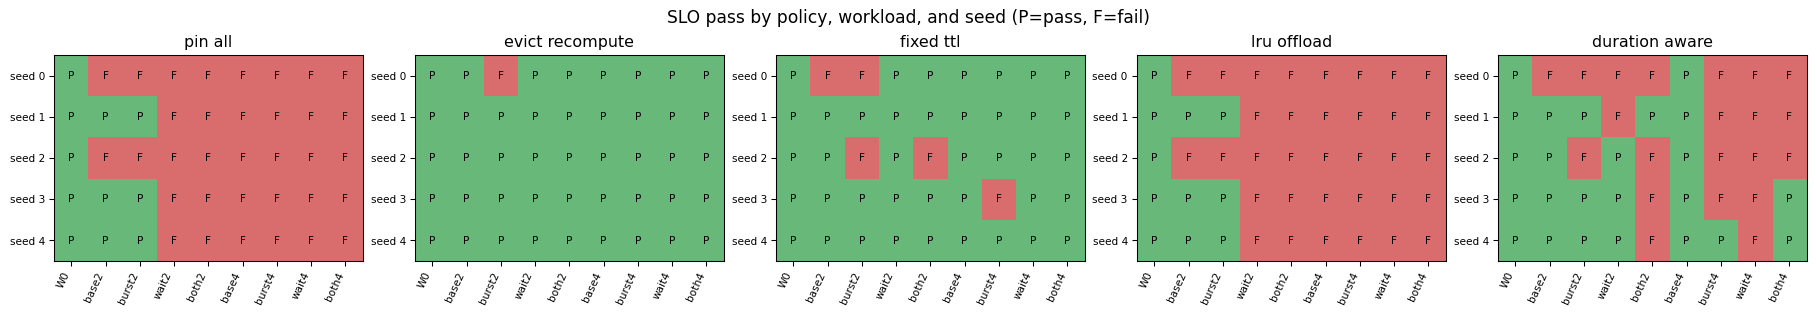

SLO 지표와 W0 대비 배율

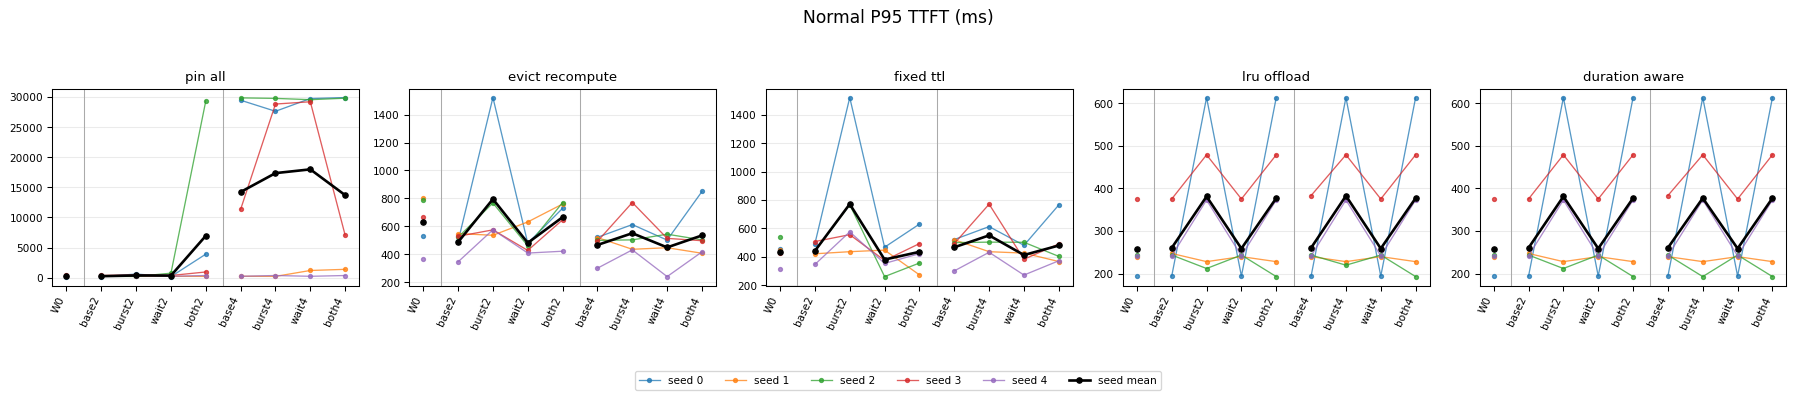

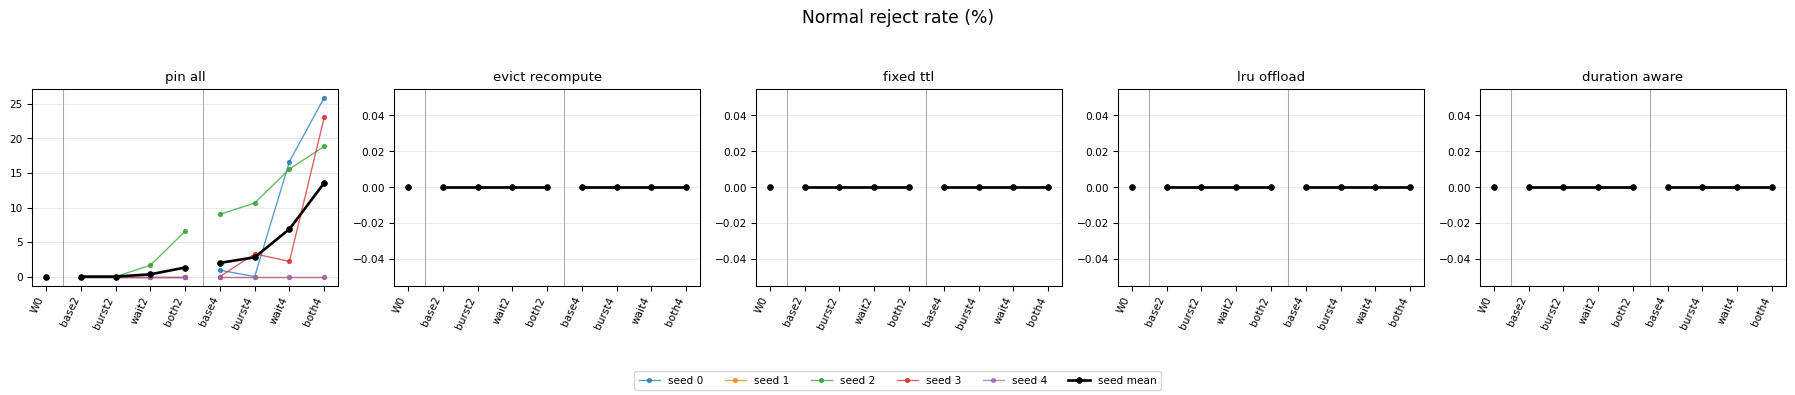

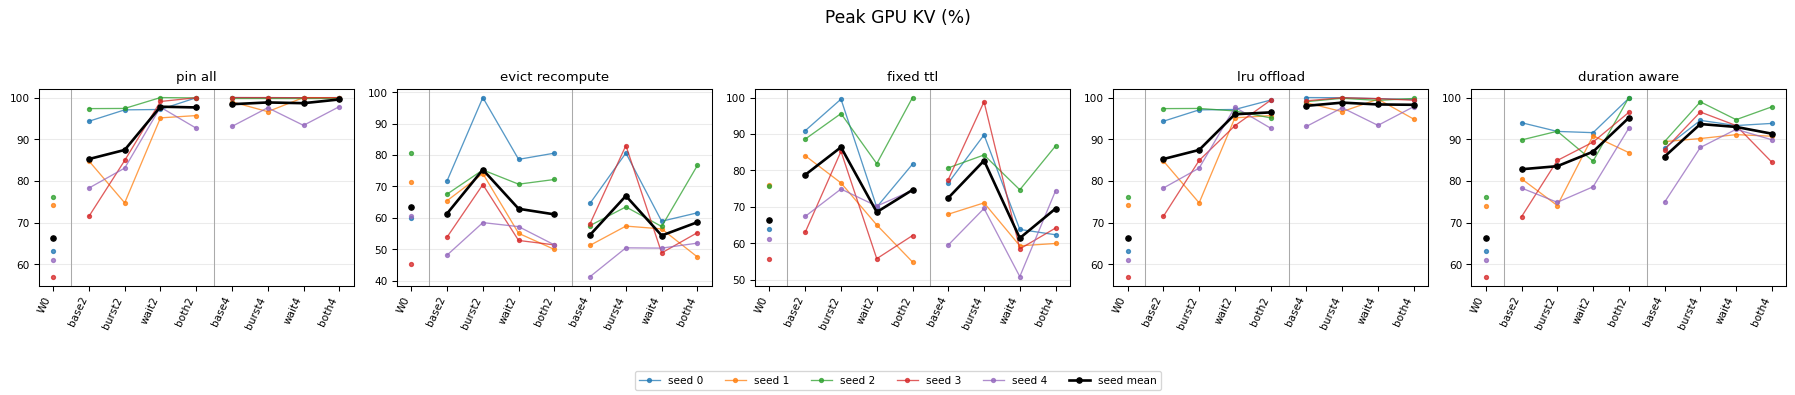

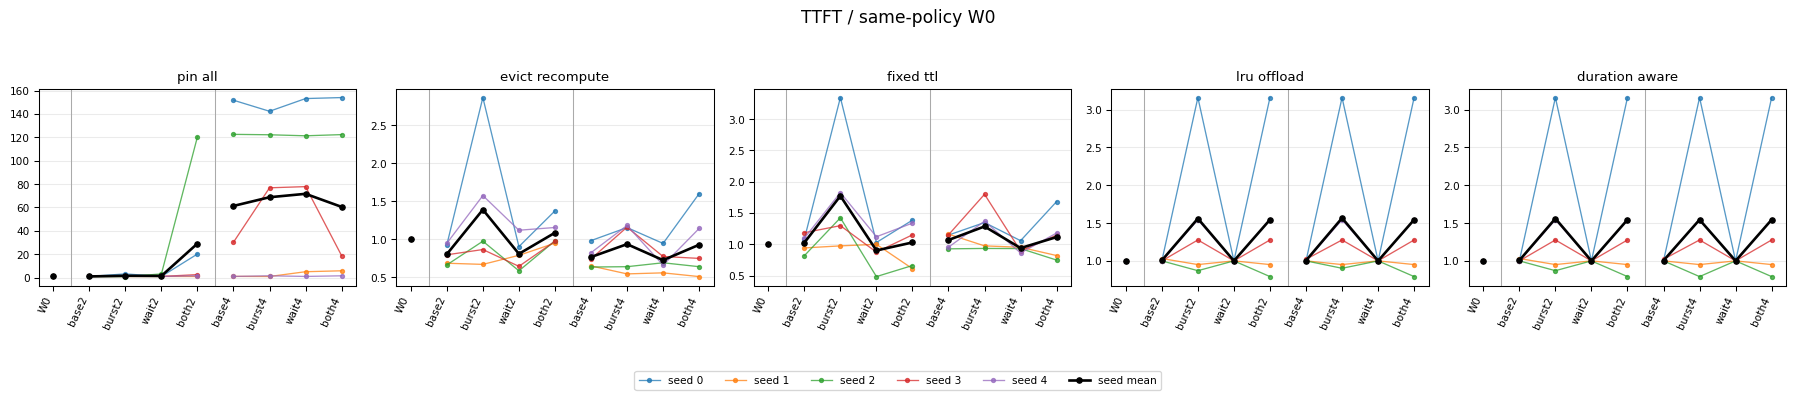

응답 지연과 작업 완료

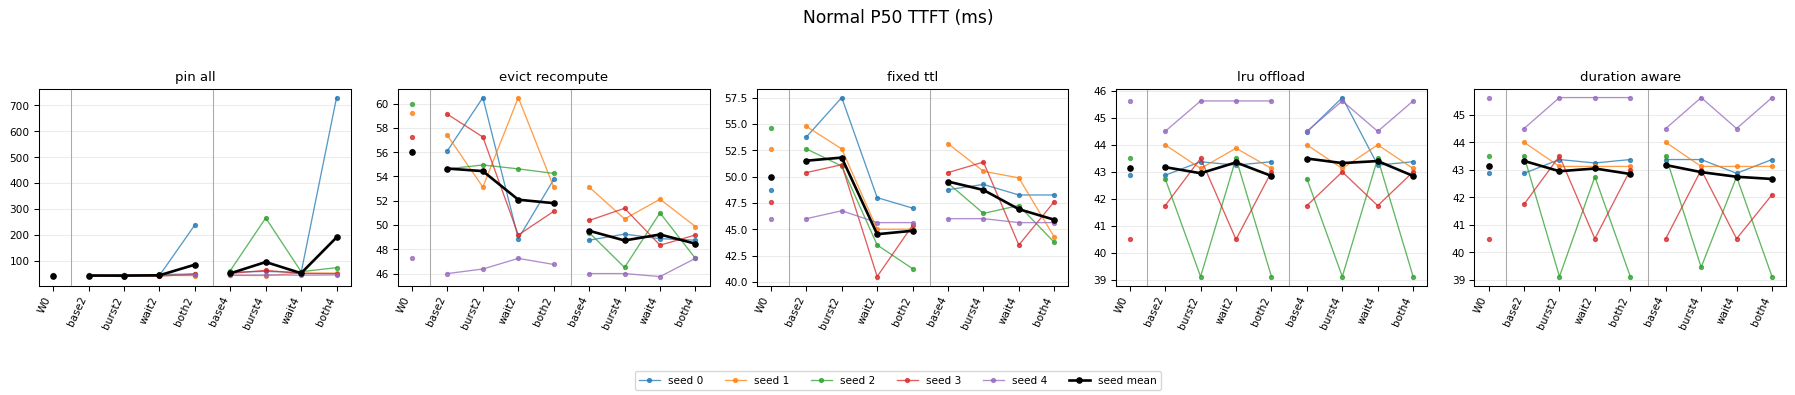

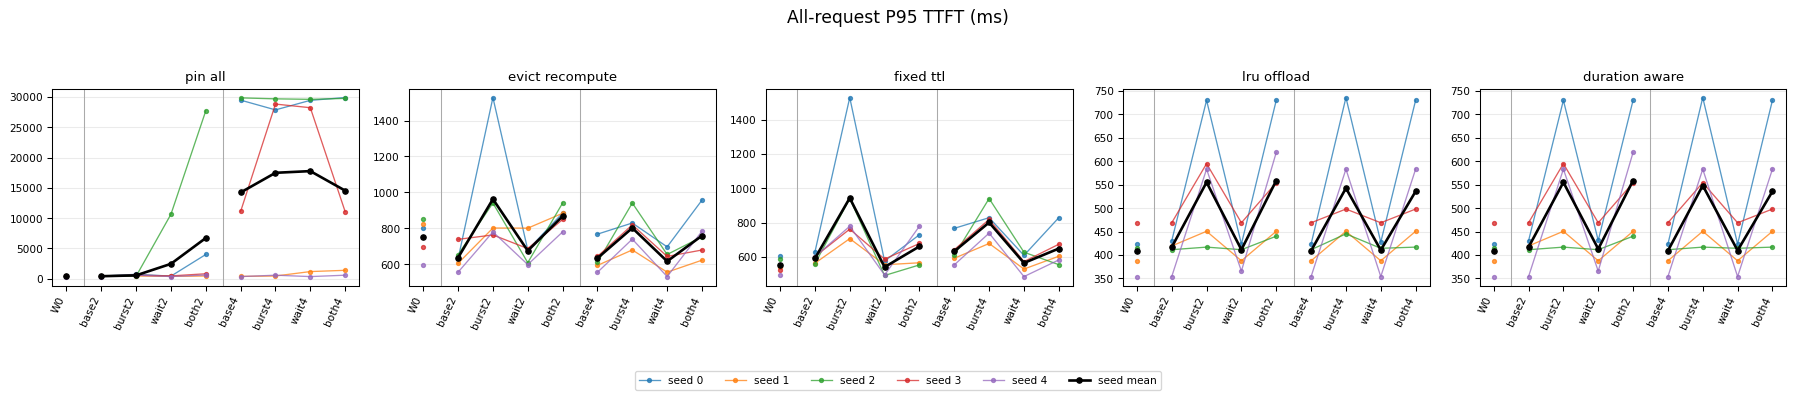

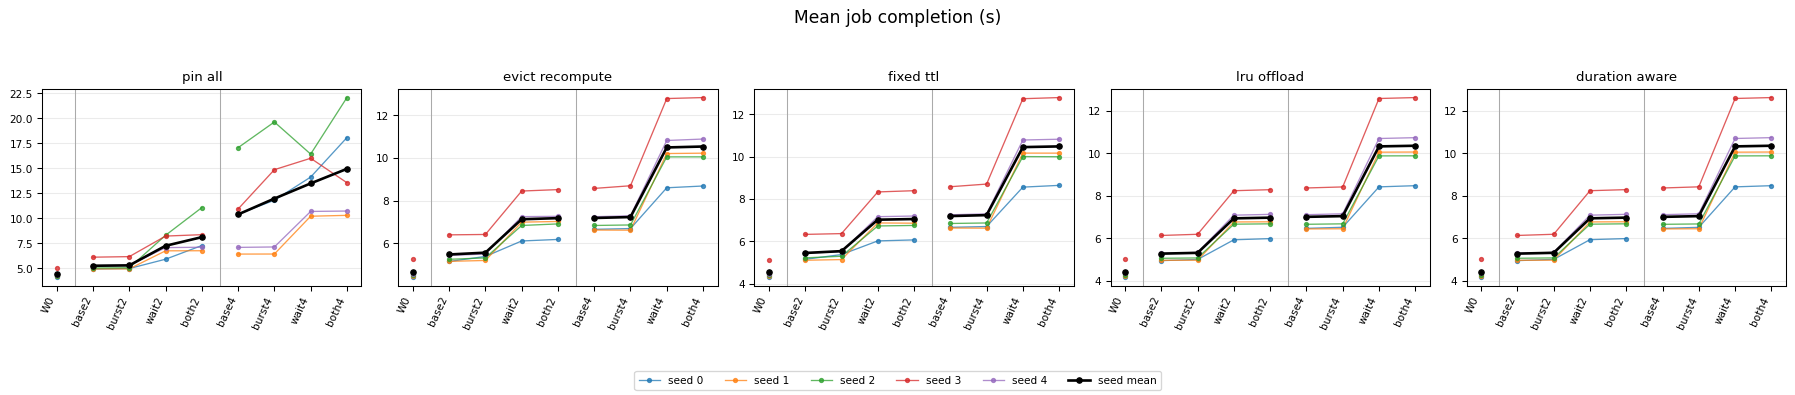

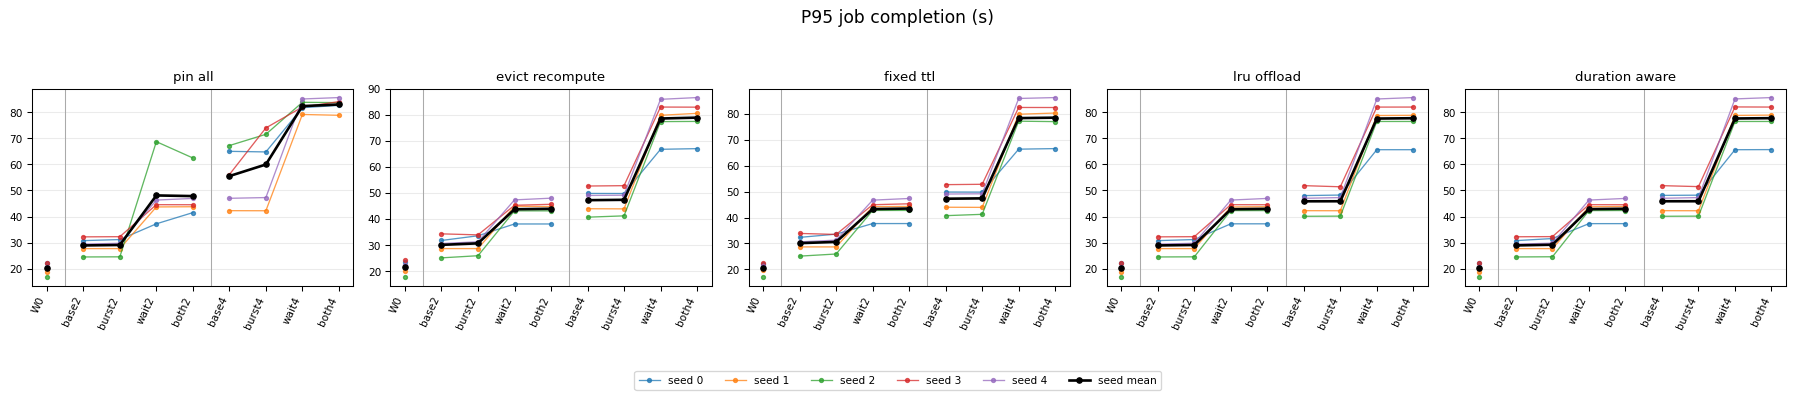

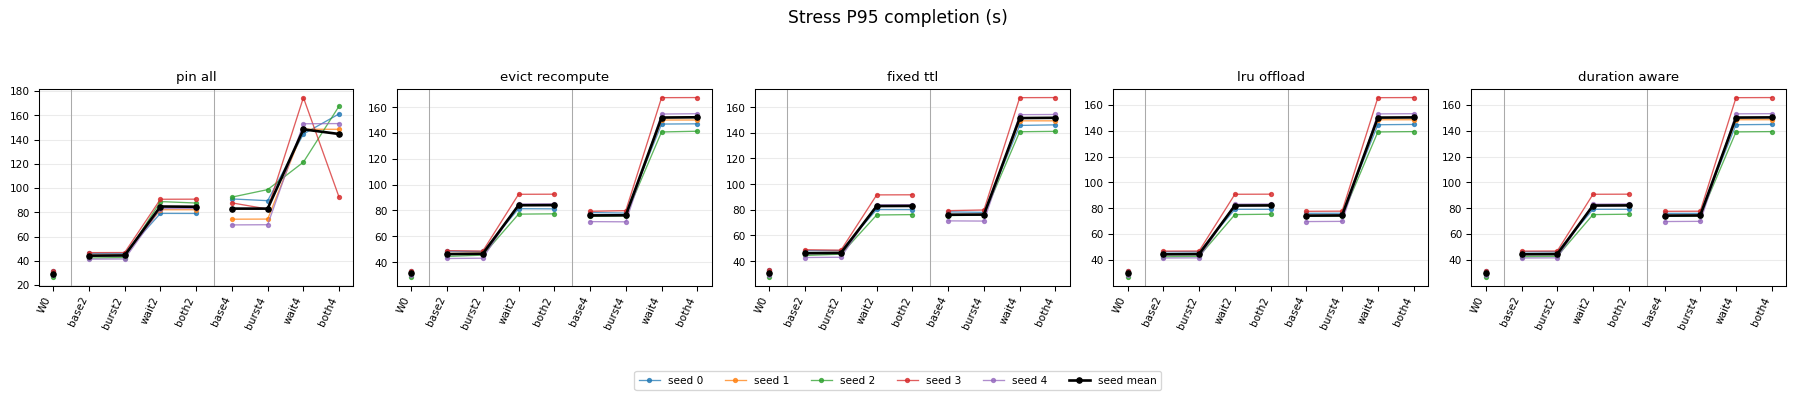

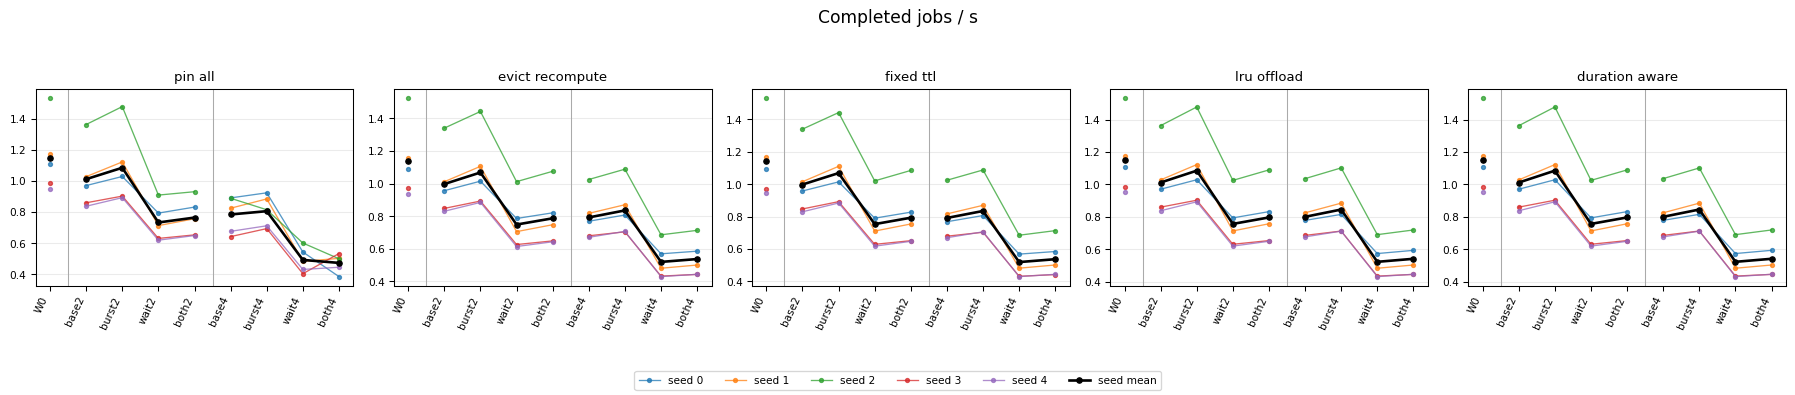

GPU KV 점유

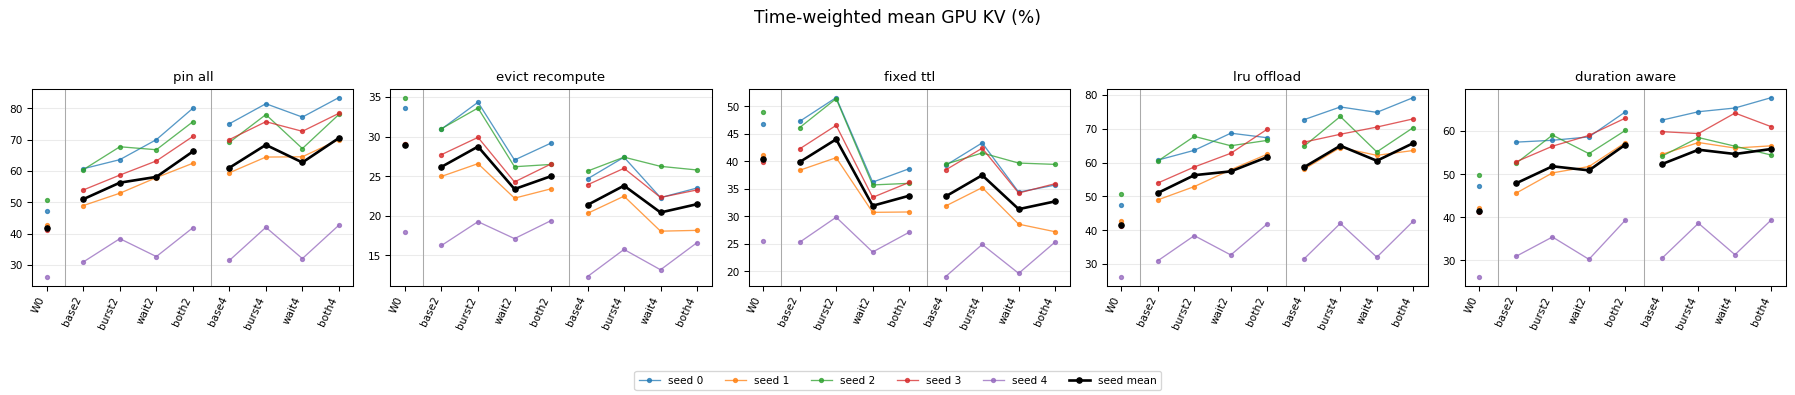

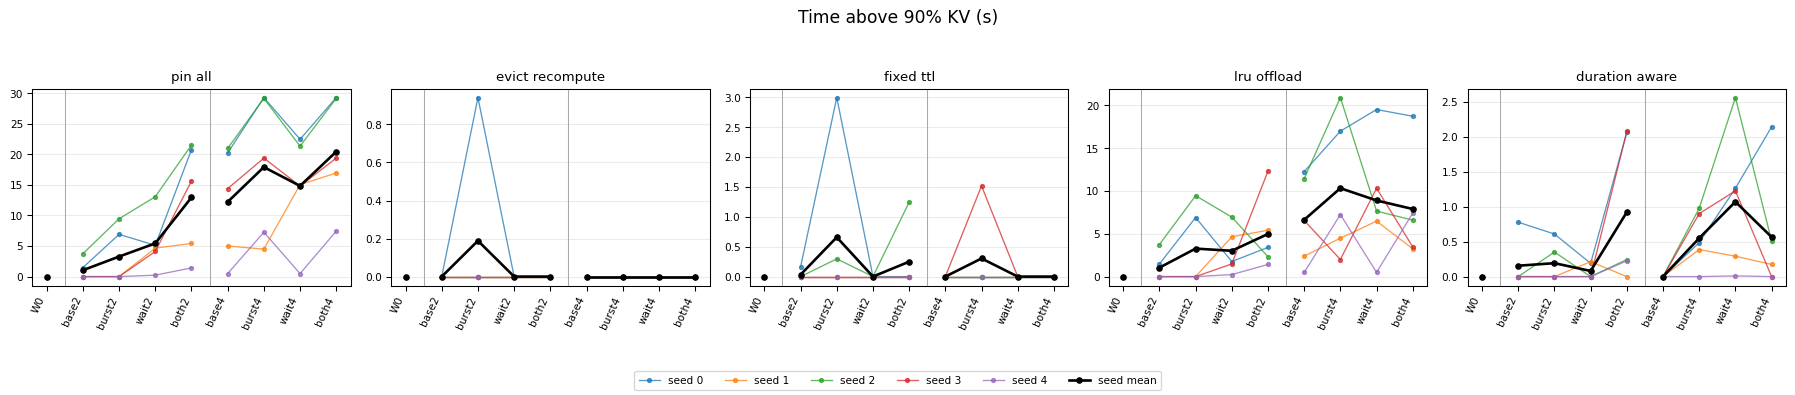

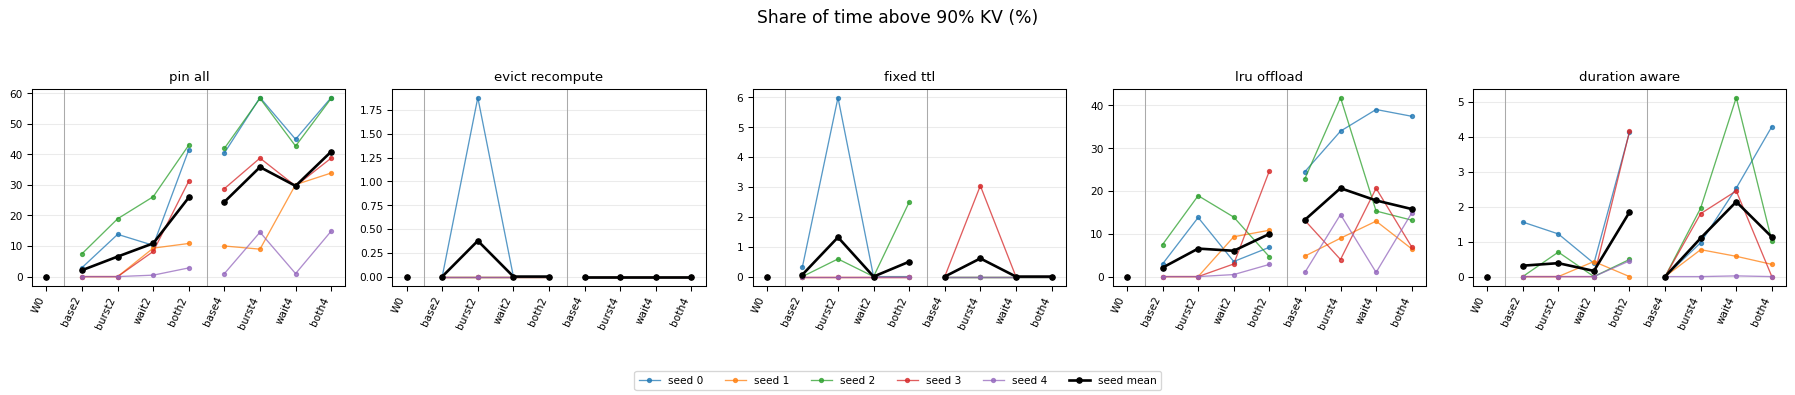

KV 관리 비용

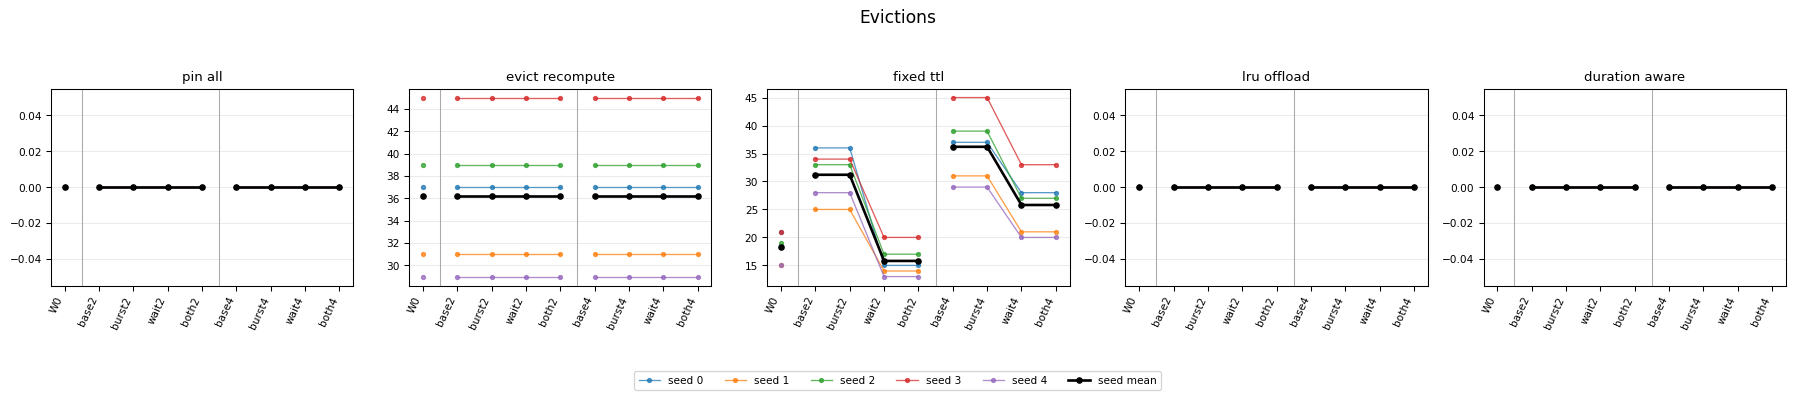

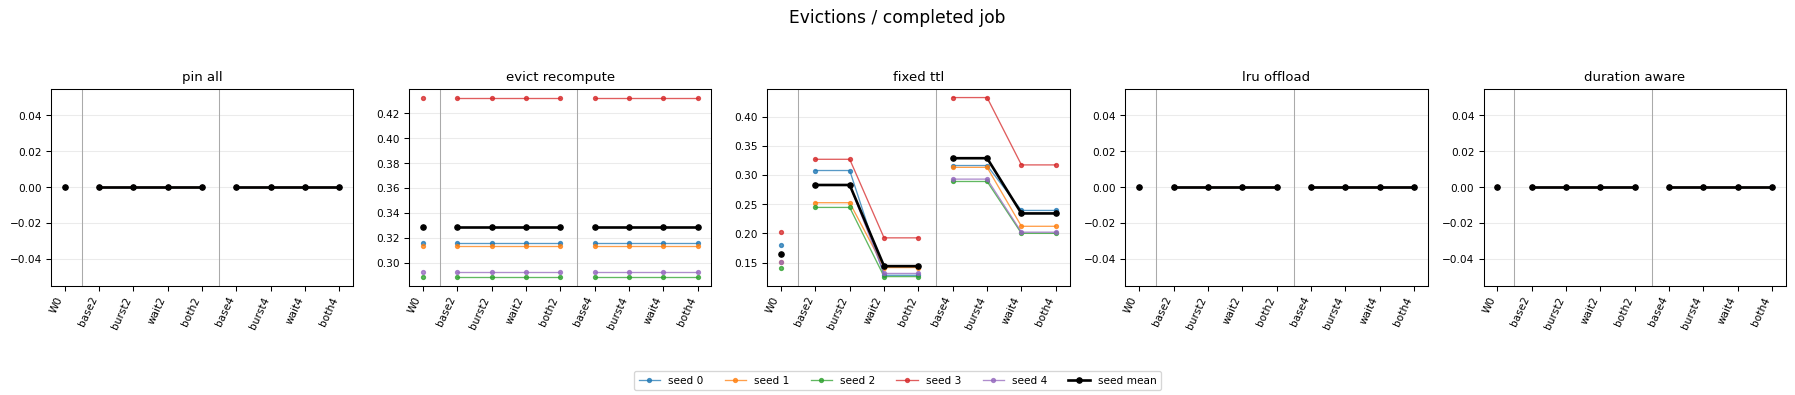

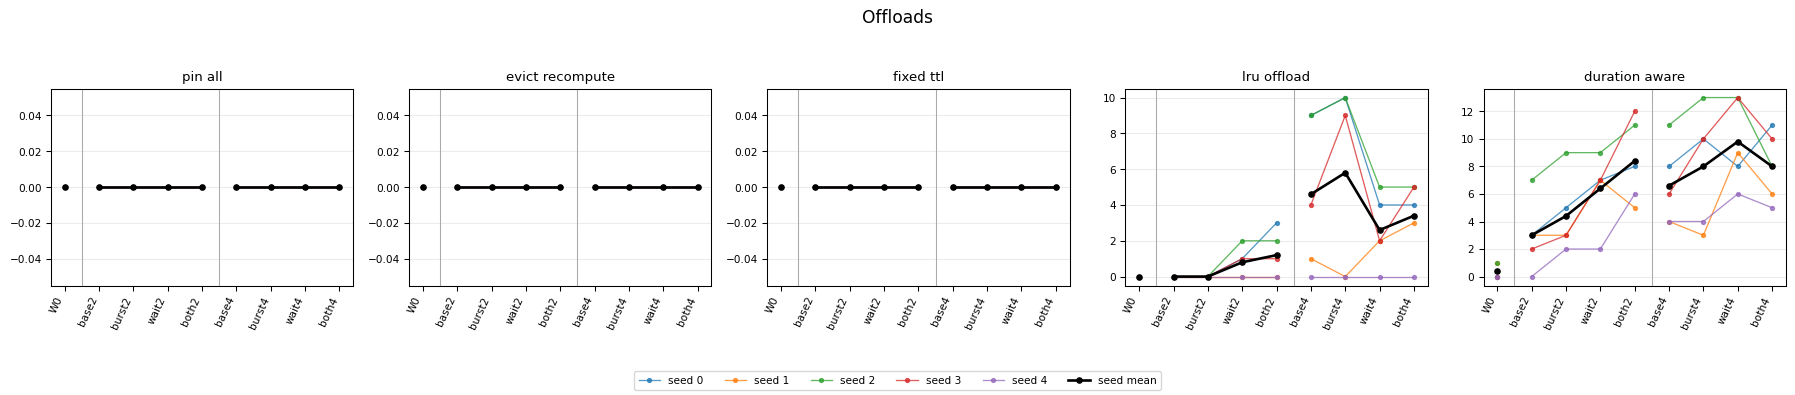

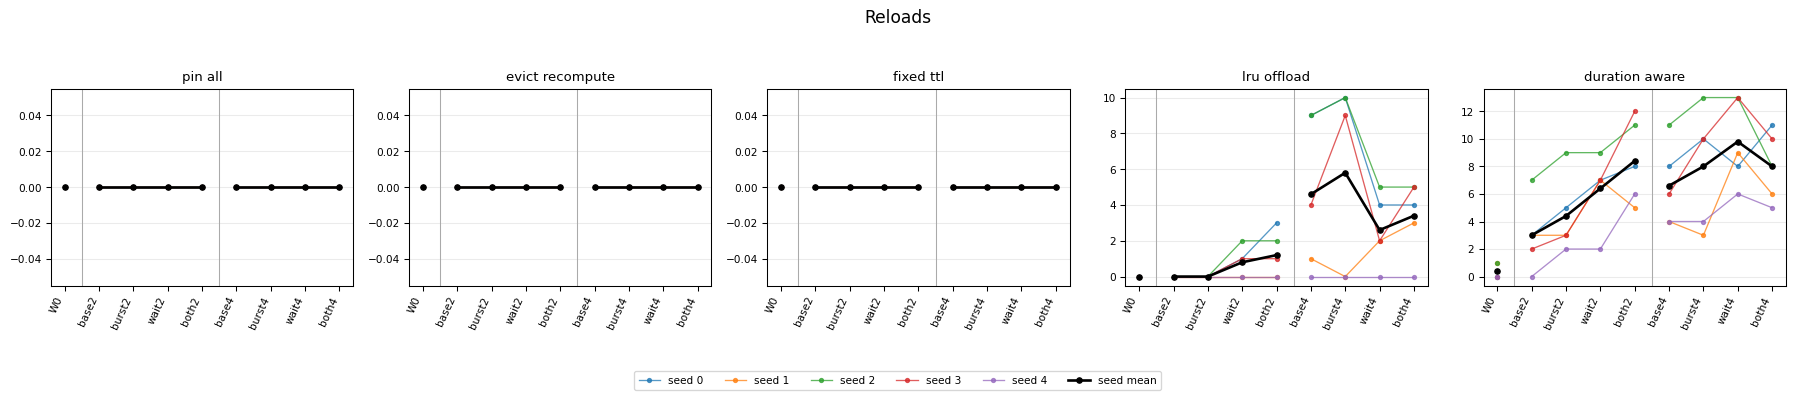

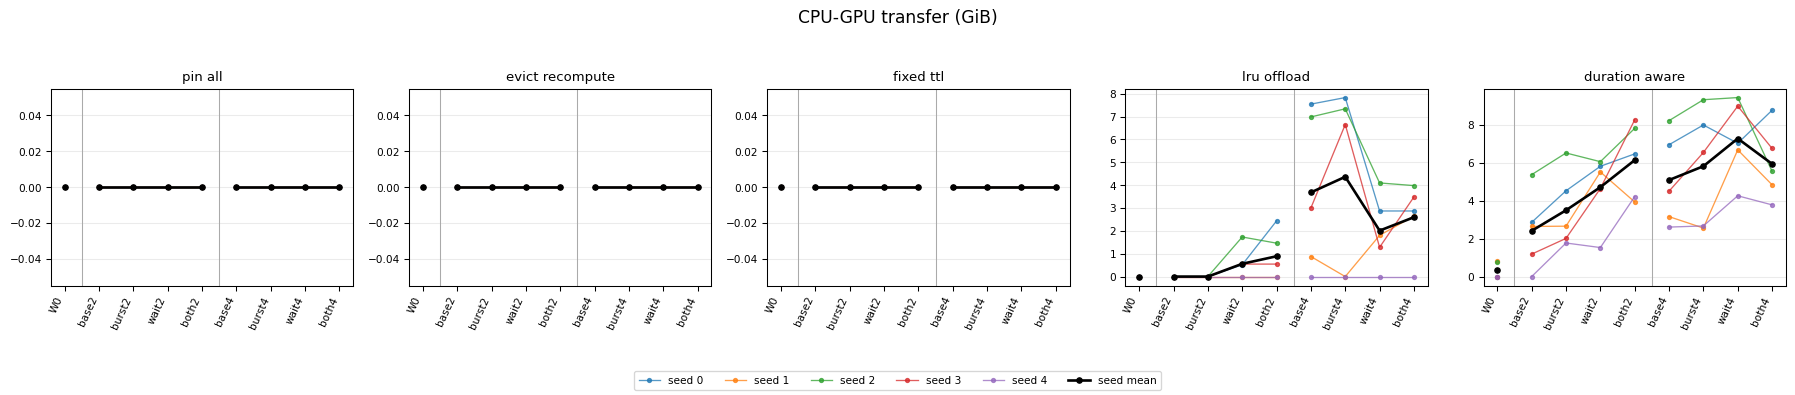

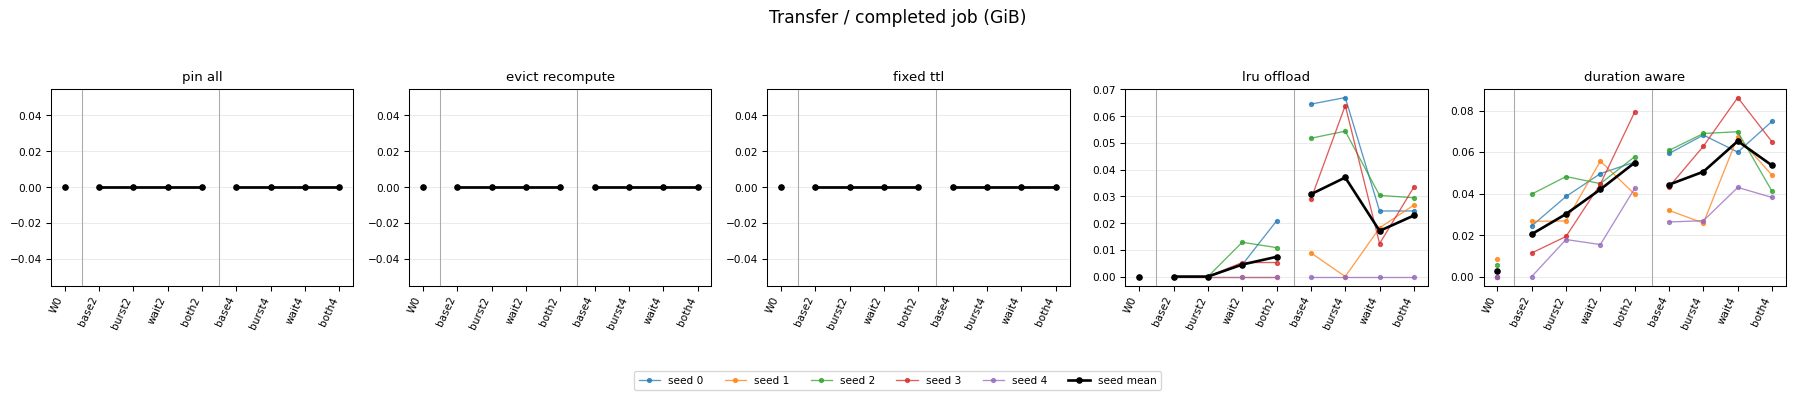

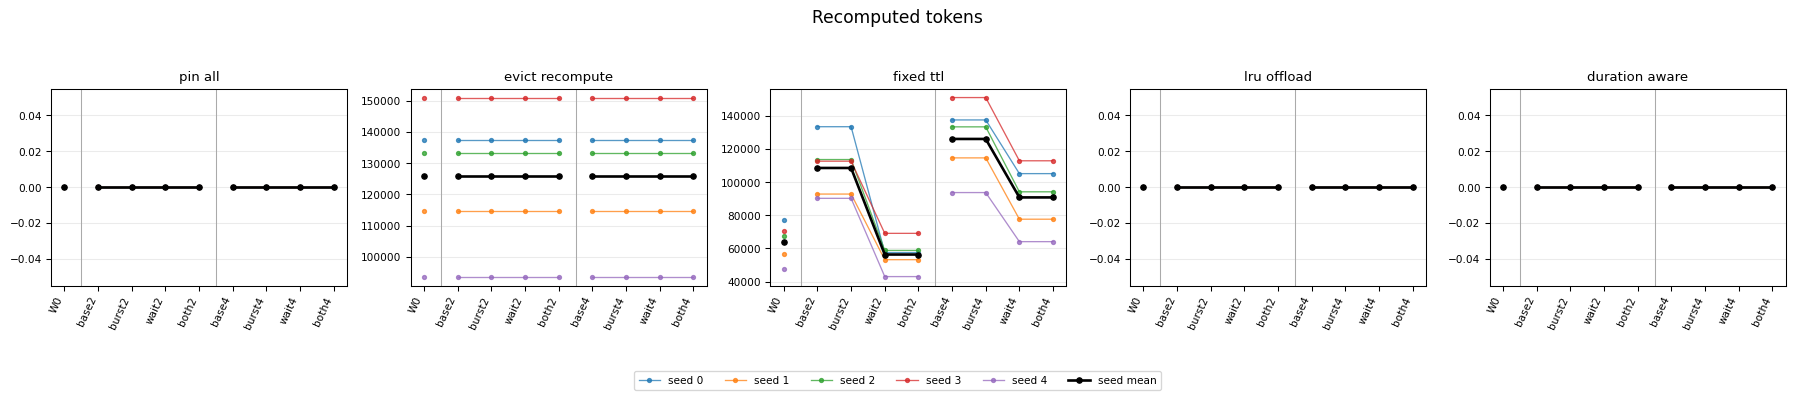

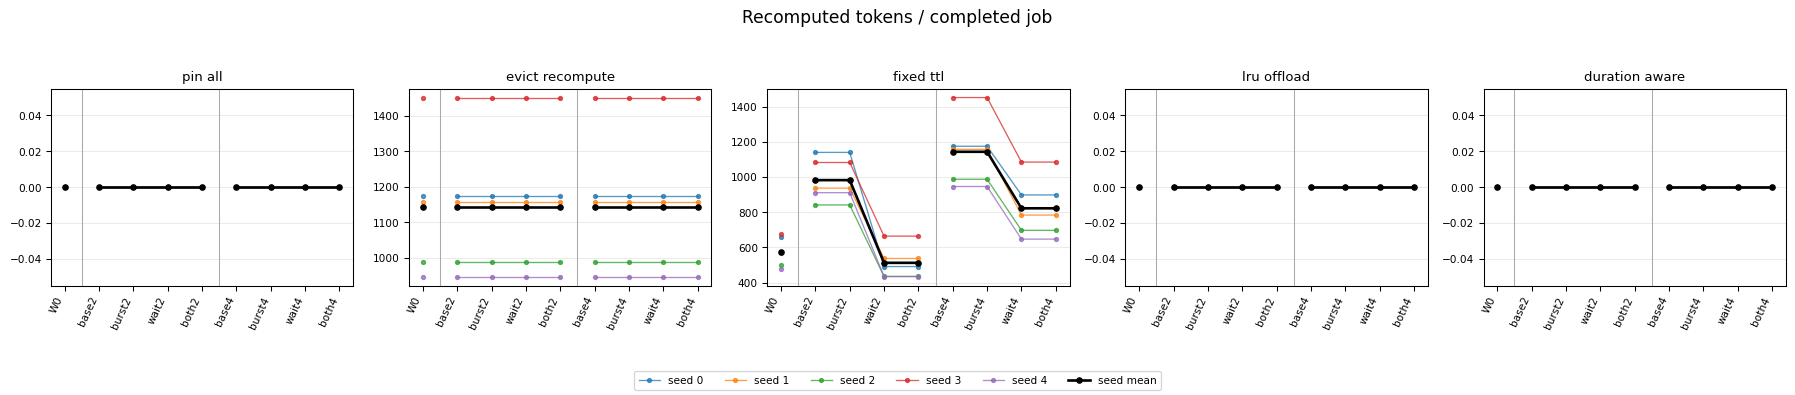

자원 사용률

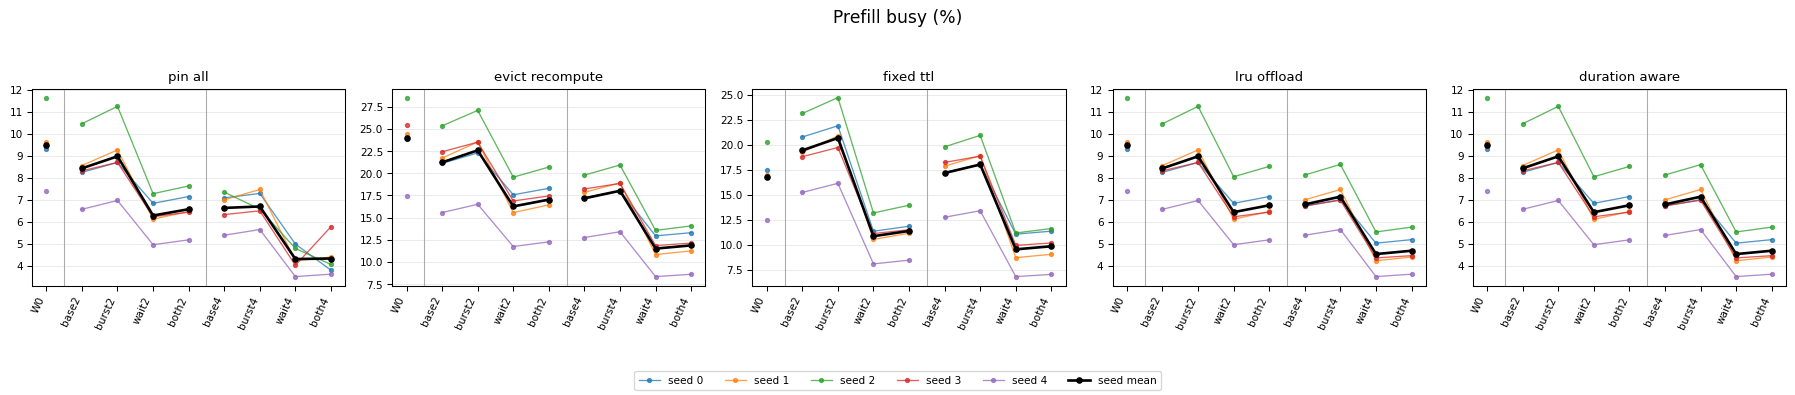

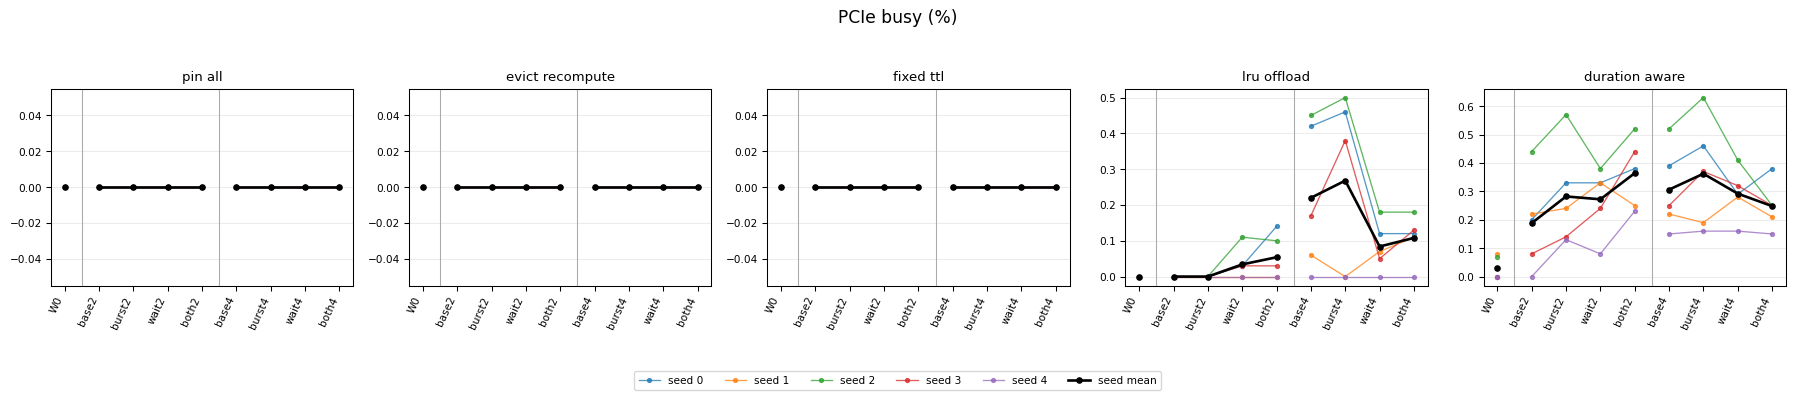

요청 수와 실행 길이

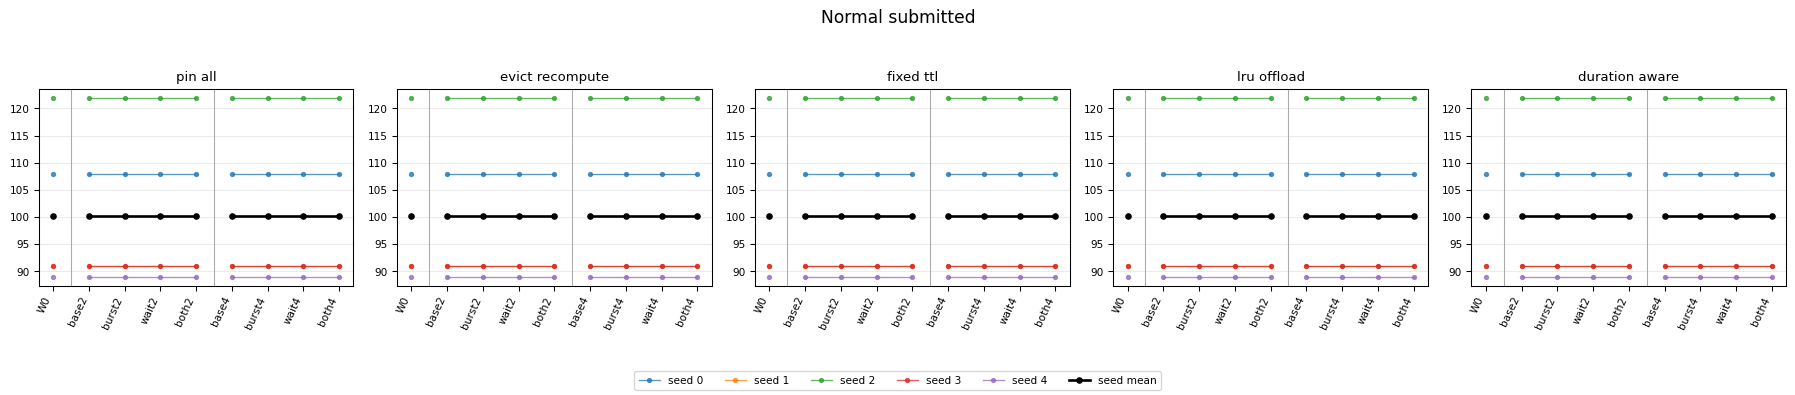

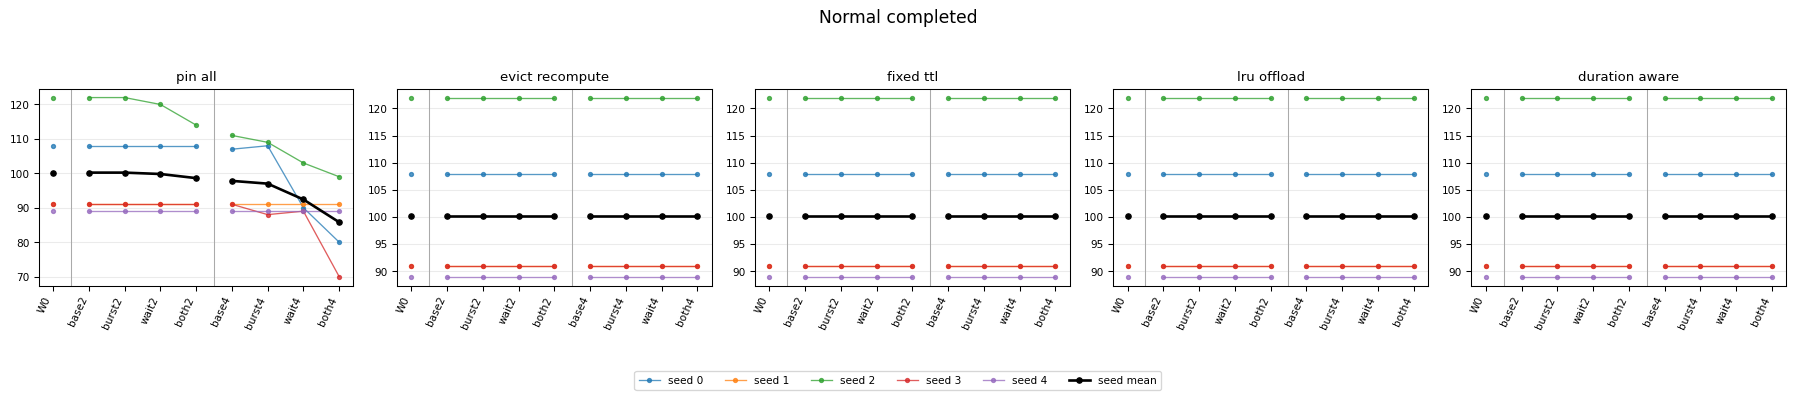

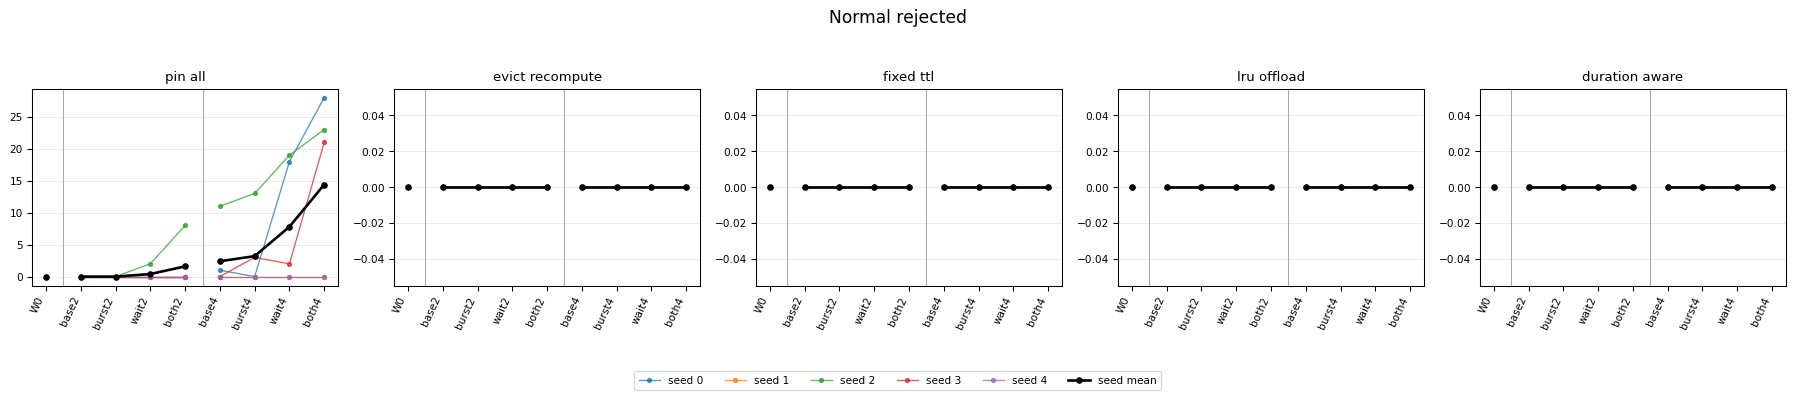

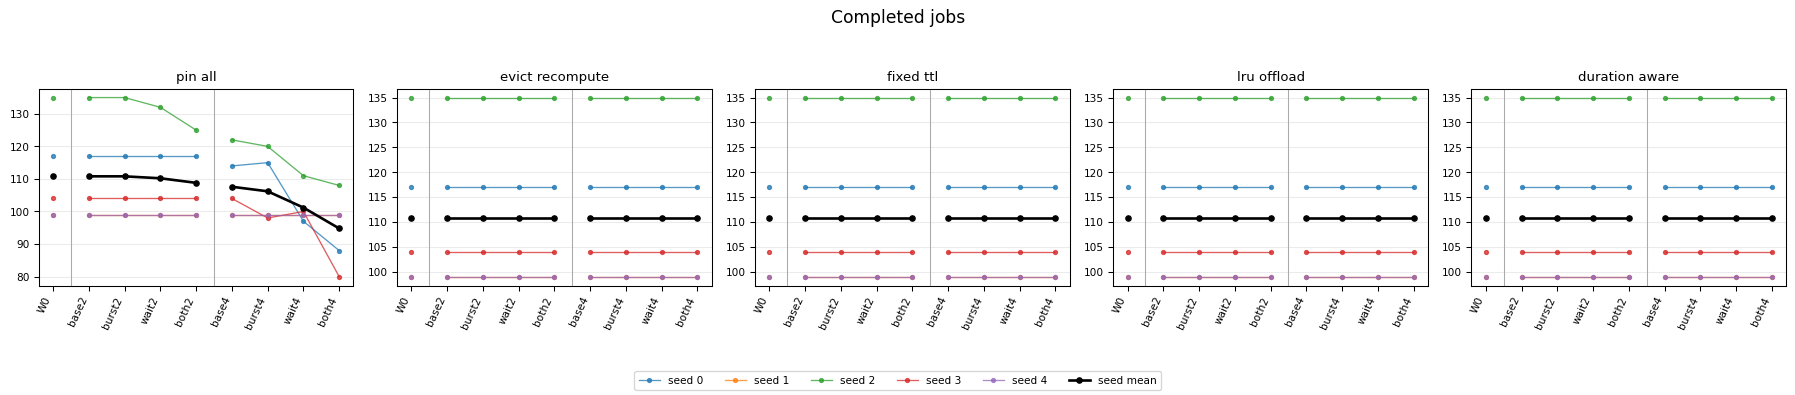

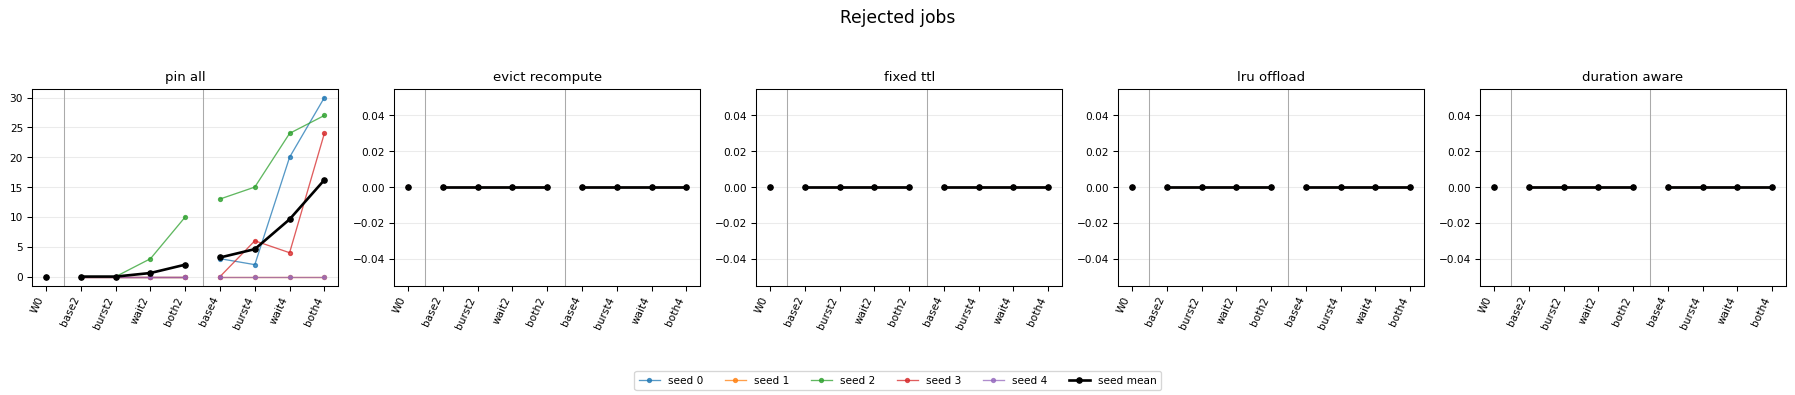

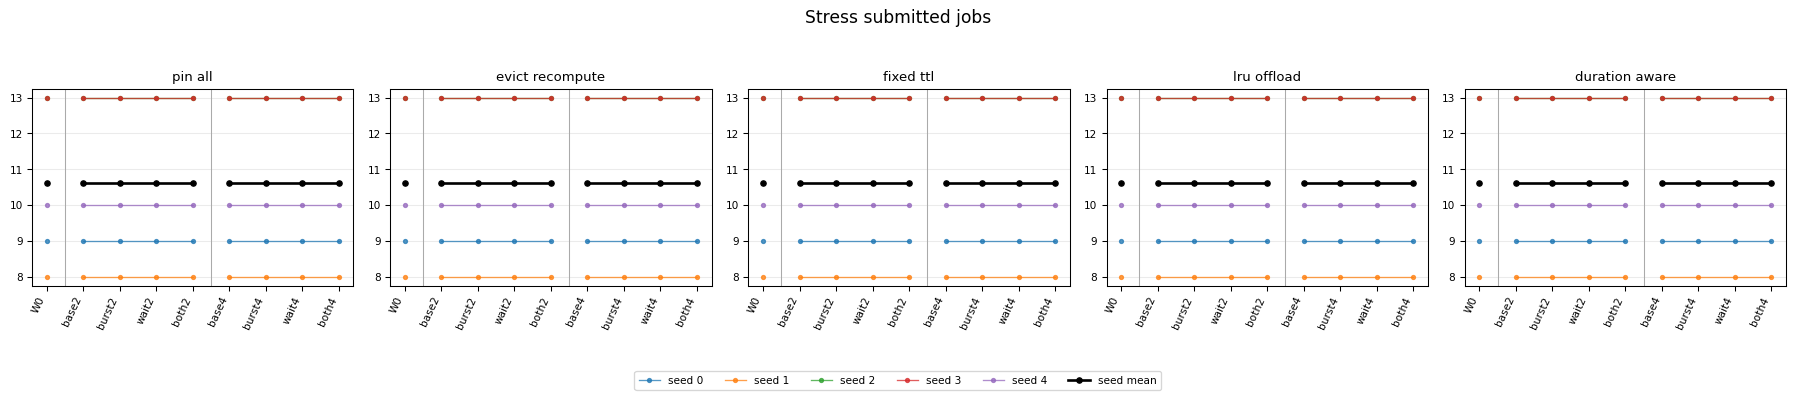

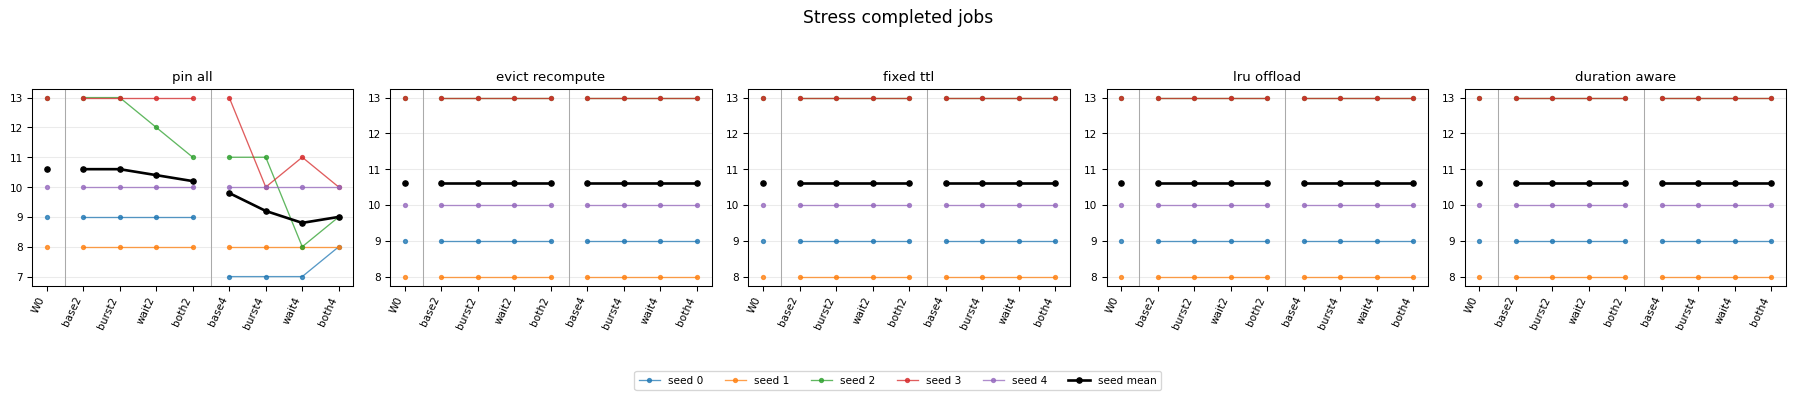

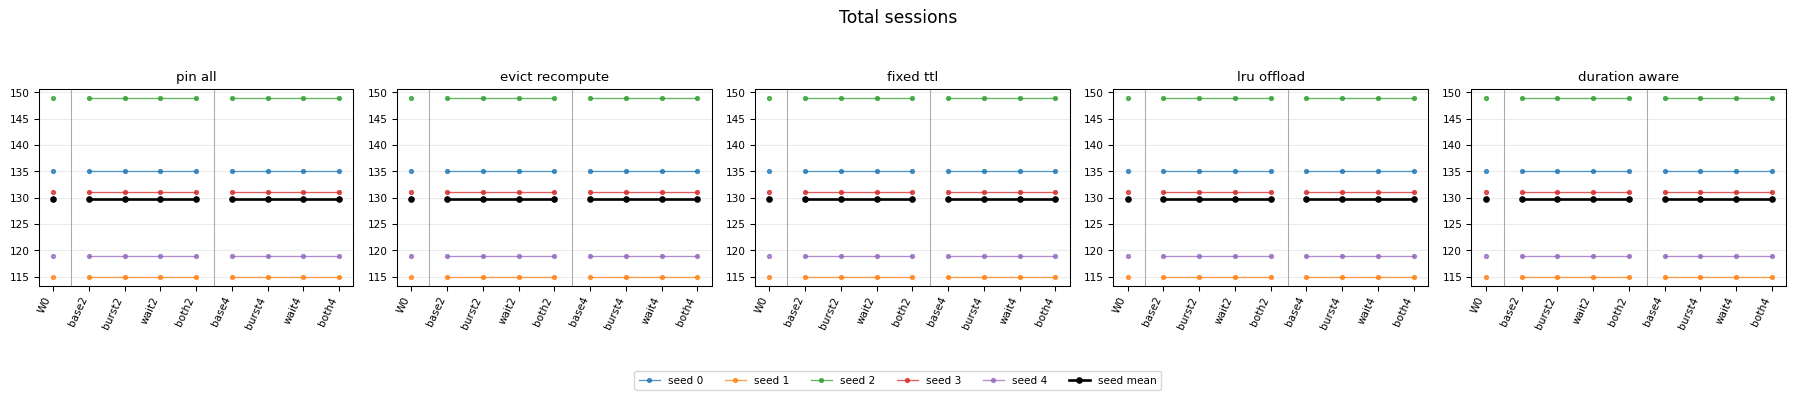

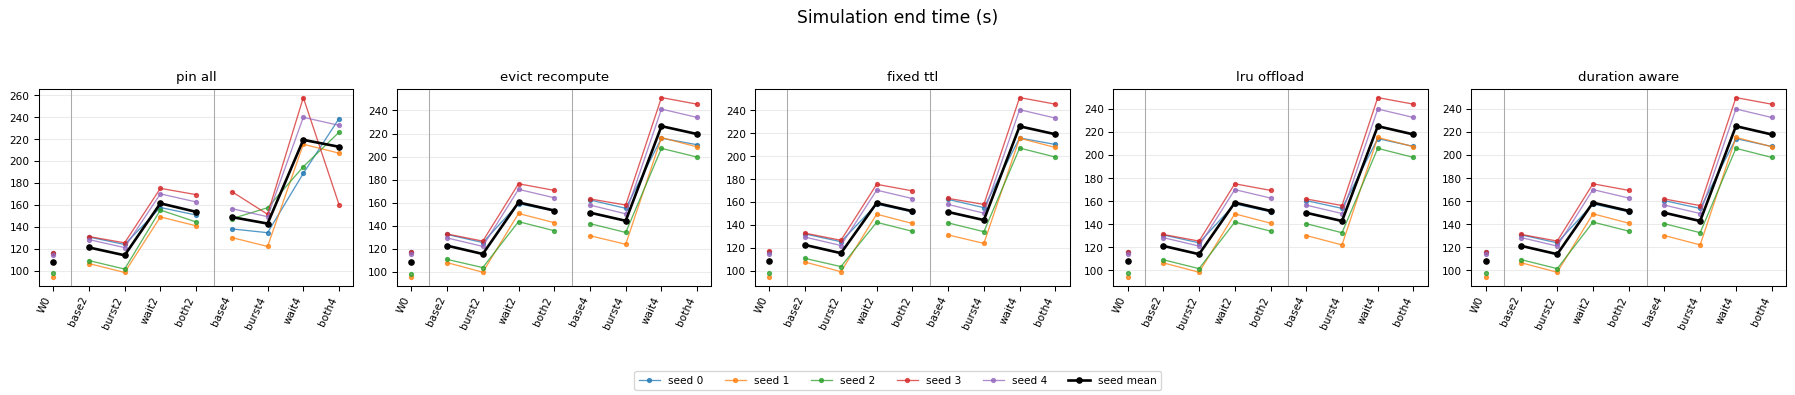

In [12]:
from matplotlib.colors import ListedColormap

load_order = [item['load'] for item in manifest['conditions']]
policy_order = list(manifest['policies'])
seed_order = list(manifest['seeds'])
x = list(range(len(load_order)))
short_labels = ['W0', 'base2', 'burst2', 'wait2', 'both2',
                'base4', 'burst4', 'wait4', 'both4']
seed_colors = plt.get_cmap('tab10').colors[:len(seed_order)]
plot_data = all_results.copy()

# (결과 컬럼, 그래프 제목, 단위 변환 계수)
metric_groups = {
    'SLO 지표와 W0 대비 배율': [
        ('normal_p95_ttft_ms', 'Normal P95 TTFT (ms)', 1),
        ('normal_reject_rate_pct', 'Normal reject rate (%)', 1),
        ('peak_kv_occupancy_pct', 'Peak GPU KV (%)', 1),
        ('ttft_ratio_vs_policy_w0', 'TTFT / same-policy W0', 1),
    ],
    '응답 지연과 작업 완료': [
        ('normal_p50_ttft_ms', 'Normal P50 TTFT (ms)', 1),
        ('all_p95_ttft_ms', 'All-request P95 TTFT (ms)', 1),
        ('task_completion_mean_ms', 'Mean job completion (s)', 1000),
        ('task_completion_p95_ms', 'P95 job completion (s)', 1000),
        ('stress_p95_completion_ms', 'Stress P95 completion (s)', 1000),
        ('throughput_jobs_per_s', 'Completed jobs / s', 1),
    ],
    'GPU KV 점유': [
        ('mean_kv_occupancy_pct', 'Time-weighted mean GPU KV (%)', 1),
        ('kv_above_90_ms', 'Time above 90% KV (s)', 1000),
        ('kv_above_90_pct_of_time', 'Share of time above 90% KV (%)', 1),
    ],
    'KV 관리 비용': [
        ('eviction_count', 'Evictions', 1),
        ('eviction_per_job', 'Evictions / completed job', 1),
        ('offload_count', 'Offloads', 1),
        ('reload_count', 'Reloads', 1),
        ('transfer_bytes', 'CPU-GPU transfer (GiB)', 2**30),
        ('transfer_gib_per_job', 'Transfer / completed job (GiB)', 1),
        ('recomputed_tokens', 'Recomputed tokens', 1),
        ('recomputed_tokens_per_job', 'Recomputed tokens / completed job', 1),
    ],
    '자원 사용률': [
        ('prefill_busy_pct', 'Prefill busy (%)', 1),
        ('pcie_busy_pct', 'PCIe busy (%)', 1),
    ],
    '요청 수와 실행 길이': [
        ('normal_submitted', 'Normal submitted', 1),
        ('normal_completed', 'Normal completed', 1),
        ('normal_rejected', 'Normal rejected', 1),
        ('completed_jobs', 'Completed jobs', 1),
        ('rejected_jobs', 'Rejected jobs', 1),
        ('stress_submitted_jobs', 'Stress submitted jobs', 1),
        ('stress_completed_jobs', 'Stress completed jobs', 1),
        ('sessions', 'Total sessions', 1),
        ('end_ms', 'Simulation end time (s)', 1000),
    ],
}
plotted = {column for group in metric_groups.values() for column, _, _ in group}
numeric_summary = set(summary.select_dtypes(include='number').columns)
config_fields = {'seed', 'stress_level', 'warmup_ms', 'measurement_end_ms'}
assert numeric_summary - config_fields <= plotted

# 정책마다 seed 행, 워크로드 열인 SLO 통과/실패 히트맵
fig, axes = plt.subplots(1, len(policy_order), figsize=(19, 3.2), constrained_layout=True)
for ax, policy in zip(axes, policy_order):
    grid = (plot_data[plot_data.policy == policy]
            .pivot(index='seed', columns='load', values='all_pass')
            .reindex(index=seed_order, columns=load_order)
            .astype(int))
    ax.imshow(grid, cmap=ListedColormap(['#d96c6c', '#68b879']), vmin=0, vmax=1, aspect='auto')
    ax.set_title(policy.replace('_', ' '))
    ax.set_xticks(x, short_labels, rotation=65, ha='right', fontsize=8)
    ax.set_yticks(range(len(seed_order)), [f'seed {seed}' for seed in seed_order], fontsize=8)
    for row in range(len(seed_order)):
        for col in x:
            ax.text(col, row, 'P' if grid.iloc[row, col] else 'F',
                    ha='center', va='center', fontsize=8, color='black')
fig.suptitle('SLO pass by policy, workload, and seed (P=pass, F=fail)', fontsize=13)
display(fig)
plt.close(fig)

# 한 지표에 5개 정책 패널을 배치하고, 각 패널에 5개 seed와 평균을 그린다.
for group_name, metrics in metric_groups.items():
    display(HTML(f'<h3>{group_name}</h3>'))
    for metric, title, divisor in metrics:
        fig, axes = plt.subplots(1, len(policy_order), figsize=(19, 4.1))
        for ax, policy in zip(axes, policy_order):
            frame = plot_data[plot_data.policy == policy]
            for seed, color in zip(seed_order, seed_colors):
                values = (frame[frame.seed == seed].set_index('load')[metric]
                          .reindex(load_order).astype(float) / divisor)
                for positions in ([0], [1, 2, 3, 4], [5, 6, 7, 8]):
                    ax.plot(positions, values.iloc[positions], color=color,
                            marker='o', markersize=3, linewidth=1, alpha=0.75,
                            label=f'seed {seed}' if positions[0] == 1 else '_nolegend_')
            average = frame.groupby('load')[metric].mean().reindex(load_order) / divisor
            for positions in ([0], [1, 2, 3, 4], [5, 6, 7, 8]):
                ax.plot(positions, average.iloc[positions], color='black',
                        marker='o', markersize=4, linewidth=2,
                        label='seed mean' if positions[0] == 1 else '_nolegend_')
            ax.axvline(0.5, color='#aaa', linewidth=0.8)
            ax.axvline(4.5, color='#aaa', linewidth=0.8)
            ax.set_title(policy.replace('_', ' '), fontsize=10)
            ax.set_xticks(x, short_labels, rotation=65, ha='right', fontsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(axis='y', alpha=0.25)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.suptitle(title, fontsize=13)
        fig.legend(handles, labels, loc='lower center', ncol=6, fontsize=8)
        fig.tight_layout(rect=(0, 0.12, 1, 0.94))
        display(fig)
        plt.close(fig)

## 9. 결과에서 얻을 수 있는 인사이트와 프로젝트 방향

이 프로젝트의 연구 질문을 **“도구를 기다리는 Agent 세션의 KV를 언제 유지·이동·삭제해야 일반 요청의 응답 품질을 지키면서 재계산·전송 부담을 줄일 수 있는가?”**로 두고 결과를 읽는다. 이 절의 근거는 이 노트북의 `week7.json`와 225회 결과다. 아래 표는 원본 CSV를 다시 대조해 만들었으며 기존 SLO 정의를 유지한다. 뒤의 연구 방향은 관측 결과에서 도출한 가설이며, 새 정책의 성능을 입증한 결과는 아니다.

In [13]:
# 원본 CSV의 지표와 seed별 SLO를 다시 대조하고, 인사이트의 근거를 모은다.
import numpy as np

insight_loads = ['w0_1x', 'both_2x', 'both_4x']
insight_rows = []
failure_rows = []
for load in insight_loads:
    for policy in manifest['policies']:
        raw = summary[(summary['load'] == load) & (summary['policy'] == policy)]
        comp = comparison[(comparison['load'] == load) & (comparison['policy'] == policy)].iloc[0]
        seed_slo = slo[(slo['load'] == load) & (slo['policy'] == policy)]
        assert len(raw) == len(seed_slo) == 5
        for metric in ['normal_p95_ttft_ms', 'normal_reject_rate_pct',
                       'peak_kv_occupancy_pct', 'kv_above_90_pct_of_time',
                       'recomputed_tokens', 'transfer_bytes']:
            assert np.isclose(raw[metric].mean(), comp[f'{metric}_mean'])
        baseline = summary[(summary['load'] == 'w0_1x') & (summary['policy'] == policy)].set_index('seed')
        paired = raw.set_index('seed').sort_index()
        ttft_ok = paired.normal_p95_ttft_ms / baseline.normal_p95_ttft_ms <= 3
        reject_ok = paired.normal_reject_rate_pct <= 10
        peak_ok = paired.peak_kv_occupancy_pct <= 90
        combined_ok = ttft_ok & reject_ok & peak_ok
        assert combined_ok.to_dict() == seed_slo.set_index('seed').all_pass.to_dict()
        insight_rows.append({
            'condition': load, 'policy': policy, 'pass_n_of_5': int(combined_ok.sum()),
            'normal_P95_ms': raw.normal_p95_ttft_ms.mean(),
            'normal_reject_pct': raw.normal_reject_rate_pct.mean(),
            'mean_of_peak_pct': raw.peak_kv_occupancy_pct.mean(),
            'time_above90_pct': raw.kv_above_90_pct_of_time.mean(),
            'recomputed_tokens_full_run': raw.recomputed_tokens.mean(),
            'transfer_GiB_full_run': raw.transfer_bytes.mean() / 2**30,
        })
        failure_rows.append({
            'condition': load, 'policy': policy,
            'TTFT_failed_seeds': int((~ttft_ok).sum()),
            'reject_failed_seeds': int((~reject_ok).sum()),
            'peak_failed_seeds': int((~peak_ok).sum()),
        })

print('핵심 지표: 각 seed의 지표를 평균한 값이며, pass는 seed별 세 조건을 모두 만족한 횟수다.')
display(pd.DataFrame(insight_rows).round(2))
print('실패 원인은 중복될 수 있다. 예: 한 seed가 TTFT와 Peak를 동시에 실패할 수 있다.')
display(pd.DataFrame(failure_rows))

coverage_rows = []
for load in ['both_2x', 'both_4x']:
    frames = []
    for run in summary[(summary['policy'] == 'duration_aware') & (summary['load'] == load)].itertuples():
        frames.append(pd.read_csv(OUTPUT / 'runs' / run.run_id / 'events.csv'))
    event_frame = pd.concat(frames, ignore_index=True)
    idle_decisions = event_frame.loc[event_frame.event == 'TOOL_START', 'detail'].str.extract(r'decision=(\w+)')[0].value_counts()
    pressure = event_frame[(event_frame.event == 'OFFLOAD_START') &
                           event_frame.detail.fillna('').str.contains('reason=pressure')]
    coverage_rows.append({
        'condition': load, 'idle_KEEP': int(idle_decisions.get('keep', 0)),
        'idle_OFFLOAD': int(idle_decisions.get('offload', 0)),
        'idle_EVICT': int(idle_decisions.get('evict', 0)),
        'pressure_OFFLOAD_starts': len(pressure),
        'all_EVICT_events': int((event_frame.event == 'EVICT').sum()),
    })
print('Duration-Aware 동작 범위: idle 진입 결정과 메모리 부족 시 동작을 구분한다. 5개 seed 합계다.')
display(pd.DataFrame(coverage_rows))

핵심 지표: 각 seed의 지표를 평균한 값이며, pass는 seed별 세 조건을 모두 만족한 횟수다.


,condition,policy,pass_n_of_5,normal_P95_ms,normal_reject_pct,mean_of_peak_pct,time_above90_pct,recomputed_tokens_full_run,transfer_GiB_full_run
0,w0_1x,pin_all,5,258.78,0.00,66.29,0.00,0.0,0.00
1,w0_1x,evict_recompute,5,629.49,0.00,63.58,0.00,126002.8,0.00
2,w0_1x,fixed_ttl,5,437.26,0.00,66.42,0.00,63749.6,0.00
3,w0_1x,lru_offload,5,258.78,0.00,66.29,0.00,0.0,0.00
4,w0_1x,duration_aware,5,258.78,0.00,66.27,0.00,0.0,0.32
5,both_2x,pin_all,0,6962.12,1.31,97.63,25.89,0.0,0.00
6,both_2x,evict_recompute,5,666.33,0.00,61.12,0.00,126002.8,0.00
7,both_2x,fixed_ttl,4,435.52,0.00,74.63,0.50,56310.8,0.00
8,both_2x,lru_offload,0,377.18,0.00,96.44,9.96,0.0,0.89
9,both_2x,duration_aware,1,377.18,0.00,95.14,1.84,0.0,6.13


실패 원인은 중복될 수 있다. 예: 한 seed가 TTFT와 Peak를 동시에 실패할 수 있다.


,condition,policy,TTFT_failed_seeds,reject_failed_seeds,peak_failed_seeds
0,w0_1x,pin_all,0,0,0
1,w0_1x,evict_recompute,0,0,0
2,w0_1x,fixed_ttl,0,0,0
3,w0_1x,lru_offload,0,0,0
4,w0_1x,duration_aware,0,0,0
5,both_2x,pin_all,2,0,5
6,both_2x,evict_recompute,0,0,0
7,both_2x,fixed_ttl,0,0,1
8,both_2x,lru_offload,1,0,5
9,both_2x,duration_aware,1,0,4


Duration-Aware 동작 범위: idle 진입 결정과 메모리 부족 시 동작을 구분한다. 5개 seed 합계다.


,condition,idle_KEEP,idle_OFFLOAD,idle_EVICT,pressure_OFFLOAD_starts,all_EVICT_events
0,both_2x,140,41,0,1,0
1,both_4x,142,39,0,1,0


### 이 설정의 결과에서 읽을 수 있는 것

1. **도구 대기 중인 KV를 관리할 필요성은 재현됐다.** W0는 다섯 정책 모두 5/5 통과하고 normal 거절률도 0%다. 반면 W2 4x에서 Pin-All의 normal P95 TTFT는 13.70초, 거절률은 13.57%다. 같은 입력에서 Duration-Aware는 377.2ms와 거절률 0%다. 도구를 기다리는 세션의 KV 처리 방식이 일반 요청의 응답에도 영향을 준다는 프로젝트의 문제 설정을 뒷받침한다.

2. **즉시 삭제는 유효한 비교 기준이지만 비용도 있다.** Evict/Recompute는 W2 2x·4x 모두 5/5 통과한다. W2 4x에서 run당 재계산은 약 126,003토큰이고 normal P95는 535.7ms다. Duration-Aware는 재계산 0, 전송 약 5.93GiB, P95 377.2ms다. “메모리를 많이 비우면 끝”이라는 결론보다, 응답 지연과 재계산·전송 비용을 함께 줄일 여지가 있다는 결과다.

3. **평균 점유율·짧은 지연과 순간 Peak는 다른 목표다.** W2 4x에서 Duration-Aware의 평균 Peak는 91.33%, 90% 초과 시간 비율은 1.13%다. LRU의 초과 비율 15.79%보다 훨씬 짧지만, Duration-Aware도 2/5만 전체 SLO를 통과한다. 따라서 과밀 구간을 줄이는 데 성공한 점과 90% 여유 공간 목표를 충족하지 못한 점을 함께 설명해야 한다.

4. **개선 후보는 대기시간 정보만이 아니라 메모리를 비우는 시점이다.** 위 Peak 사례(seed 2)는 30.991초의 ADMIT 직후 97.78%가 되고, 근처의 다음 idle offload 결정은 31.387초다. 이 한 사례는 현재 결정 시점과 입장 시 예약이 순간 Peak를 놓칠 수 있음을 보여준다. 모든 seed의 원인이 같다고 단정하지 말고, Peak 당시 active·idle·전송 중 KV를 분해해서 확인할 가설로 둔다.

5. **현재 결과는 3가지 행동을 고르는 정책 전체를 검증한 결과가 아니다.** W2 2x의 idle 결정은 KEEP 140회·OFFLOAD 41회, 4x는 142회·39회이며 EVICT 이벤트는 모두 0회다. CPU 64GiB와 빠른 PCIe 가정에서는 OFFLOAD가 유리한 분기가 넓다. 실제 미래 대기를 사용하는 oracle 입력도 현재 휴리스틱을 최적으로 만들지는 않는다. 따라서 이 결과로 현실 예측기 성능이나 KEEP/OFFLOAD/EVICT의 최적 선택을 주장할 수 없다.

### 도구 대기에 가려진 모델·스케줄링 시간을 함께 보기

위 그래프의 stress 작업 완료 P95에는 도구를 기다리는 시간이 들어간다. 다음 표는 **완료한 각 작업의 전체 시간에서 그 작업의 도구 대기 합을 먼저 뺀 뒤**, run별 P95와 seed 평균을 구한다. 이 값에는 decode·prefill·입장 대기·재계산·reload가 함께 포함되므로 KV 정책만의 순수한 비용은 아니다. 완료 수가 적은 정책에는 살아남은 작업만 남는 편향이 있으므로, 표의 완료 수와 normal 거절을 반드시 함께 본다.

In [14]:
# 보조 진단: 완료한 stress 작업마다 실제 도구 대기 합을 뺀 뒤 P95를 구한다.
# 두 P95를 빼는 방식이 아니다. 이 값에도 decode, prefill, 입장 대기, 복구가 포함된다.
from kvbench.metrics import percentile

non_tool_rows = []
trace_jobs_cache = {}
for run in summary[summary['load'].isin(['w0_1x', 'both_4x'])].itertuples():
    if run.trace not in trace_jobs_cache:
        trace = pd.read_json(OUTPUT / 'traces' / run.trace, lines=True)
        stress_trace = trace[trace.request_class == 'stress']
        trace_jobs_cache[run.trace] = stress_trace.groupby('session_id').agg(
            initial_arrival_ms=('session_arrival_ms', 'first'),
            tool_wait_sum_ms=('tool_duration_ms', 'sum'),
            expected_turns=('expected_turns', 'first'),
        )
    jobs = trace_jobs_cache[run.trace]
    requests = pd.read_csv(OUTPUT / 'runs' / run.run_id / 'requests.csv')
    values = []
    for sid, turns in requests[requests.request_class == 'stress'].groupby('session_id'):
        job = jobs.loc[sid]
        if job.initial_arrival_ms < manifest['workload_config']['warmup_ms']:
            continue
        if len(turns) != int(job.expected_turns) or not (turns.outcome == 'completed').all():
            continue
        assert turns.turn_id.nunique() == int(job.expected_turns)
        elapsed = turns.complete_ms.max() - job.initial_arrival_ms
        non_tool = elapsed - job.tool_wait_sum_ms
        assert non_tool >= -1e-6
        values.append(max(non_tool, 0))
    assert len(values) == run.stress_completed_jobs
    non_tool_rows.append({
        'condition': run.load, 'policy': run.policy, 'seed': run.seed,
        'completed_stress_jobs': len(values),
        'non_tool_stress_P95_ms': percentile(values, 95),
    })

non_tool = pd.DataFrame(non_tool_rows)
non_tool_table = non_tool.groupby(['condition', 'policy']).agg(
    mean_completed_stress_jobs=('completed_stress_jobs', 'mean'),
    mean_of_non_tool_P95_s=('non_tool_stress_P95_ms', lambda values: values.mean() / 1000),
)
display(non_tool_table.round(3))
print('완료 작업만의 P95다. 완료 수가 다른 정책은 거절·중단으로 표본이 달라지므로 함께 비교해야 한다.')

mean_completed_stress_jobs  mean_of_non_tool_P95_s
condition policy                                                             
both_4x   duration_aware                         10.6                  15.984
          evict_recompute                        10.6                  17.931
          fixed_ttl                              10.6                  17.823
          lru_offload                            10.6                  15.968
          pin_all                                 9.0                  36.862
w0_1x     duration_aware                         10.6                  15.683
          evict_recompute                        10.6                  17.654
          fixed_ttl                              10.6                  16.960
          lru_offload                            10.6                  15.683
          pin_all                                10.6                  15.683

완료 작업만의 P95다. 완료 수가 다른 정책은 거절·중단으로 표본이 달라지므로 함께 비교해야 한다.


### 프로젝트의 다음 판단과 실험 순서

이 60초 설정은 **정책 간 차이와 실패 원인을 확인하는 초기 실험**으로 쓰는 것이 적절하다. 짧은 입력 구간에서는 긴 도구 대기 중 다음 세션이 충분히 누적되기 전에 새 도착이 끝날 수 있다. drain으로 모든 작업을 끝까지 처리하더라도, 새 세션이 계속 들어오는 장시간 부하를 대신하지는 못한다.

다음에는 같은 도착률에서 기간을 늘리고, 평균을 맞춘 도구 대기 분포와 버스트를 별도로 비교해 원인을 확인한다. 기존 180초 노트북과 함께 보면, 60초에서의 W0 안전성이 장시간에도 유지되는지를 검토할 수 있다. 새로운 정책의 성공 기준은 **일반 요청 SLO를 지키면서 Evict/Recompute의 재계산 부담이나 기존 offload 정책의 과밀·전송 부담을 얼마나 줄이는가**로 사전에 고정하는 것이 좋다.

이 추가 진단에서 W2 4x의 도구 대기 제외 P95는 Duration-Aware가 약 15.98초, Evict/Recompute가 약 17.93초다. 원래 stress 완료시간만 보면 가려질 수 있는 차이다. 이 값도 생성 시간 전체를 포함하므로, 정책의 직접 비용을 확인하려면 이후 입장 대기·prefill 대기·복구 시간을 따로 분해하는 편이 좋다.

다음 정책 구현 전에 우선 확인할 사항은 세 가지다.

1. **평가 목표를 고정한다.** 기존 SLO를 보존하고 서비스 요구에 근거한 절대 normal TTFT 목표, stress 완료율, 메모리 여유 목표를 정한다. Peak를 엄격히 제한할지, 초과 지속시간도 운영 목표로 둘지는 실험 전에 결정한다. 결과를 보고 유리한 기준으로 바꾸지 않는다.
2. **원인과 정책의 선택 범위를 검증한다.** Peak의 KV 소유 상태, 전송 대기열, 입장 대기, 실행된 KEEP/OFFLOAD/EVICT를 확인한다. 평균을 맞춘 대기 분포, 더 느린 PCIe·작은 CPU 풀, 대기 예측 오차 등을 별도 조건으로 두어 지금 거의 평가되지 않은 선택 구간도 확인한다. 파라미터를 고른 seed와 최종 평가 seed를 구분하고, 다섯 seed의 통과율을 일반적인 확률로 단정하지 않는다.
3. **시뮬레이터와 실제 실행 사이를 연결한다.** 실제 대상 환경에서 prefill·decode·KV 크기·전송 속도를 보정하고 민감도를 본다. 현재 모델은 고정 decode 속도와 단일 FIFO prefill·PCIe를 가정하므로, 절대 ms나 GiB 수치를 실제 GPU 성능으로 주장할 수 없다.

현재 단계의 기여는 **통제된 입력에서 정책의 지연·메모리·복구 비용 차이를 재현하고, 개선이 필요한 실패 원인을 좁히는 것**이다. 이후 개선안을 평가할 때도 한 통과율의 상승뿐 아니라, 같은 서비스 목표에서 무엇을 줄이고 어떤 비용을 더 썼는지를 설명해야 한다.

### 이 인사이트를 읽을 때 고정할 지표 정의

- 표의 TTFT와 Peak는 **seed별 P95 또는 Peak를 구한 뒤 5개 seed에서 평균**한 값이다. 전체 요청을 합쳐 구한 P95가 아니며, 평균 Peak가 90% 미만이어도 일부 seed는 실패할 수 있다.
- 현행 SLO는 정책별 자기 W0 대비 TTFT 비율을 쓴다. 빠른 W0를 가진 정책에 상대 기준이 더 까다로울 수 있고, 느린 W0는 큰 지연도 통과시킬 수 있다. 절대 TTFT·거절률·작업 완료 수를 함께 본다. 실패한 요청은 완료 요청 TTFT 표본에 들어가지 않는다.
- Peak는 warmup 이후 **drain 종료까지**, 평균 점유율·90% 초과 비율은 **입력 기간 끝까지**다. 전송량·재계산·evict/offload 횟수는 **warmup과 drain을 포함한 전체 run 누계**다. 현재 per-job 비용은 이 누계를 warmup 이후 완료 수로 나눈 값이므로, 엄밀한 효율 비교 전에는 분자·분모 구간을 맞춰야 한다.
- 90%는 평가에서 정한 여유 공간 목표다. 현재 입장 로직은 실제 풀 용량인 100% 안에서 할당하며, 모든 정책이 90% 상한을 유지하도록 구현된 것은 아니다. 실패를 없애려고 사후에 기준을 바꾸지 않고, Peak와 초과 지속시간을 함께 보고한다.
- `base→burst`는 도착 집중의 대비다. `base→wait`에는 교대 패턴과 평균 대기 증가가 함께 들어간다. 2x보다 4x가 좋은 지표가 있어도, 대기 연장으로 복귀 시각이 분산되거나 TTL이 더 많이 만료된 결과일 수 있다. 현 결과만으로 단조 관계나 순수 변동성 효과를 주장하지 않는다.